# SUPERESTELA — Pipeline final publicado: Stuff+ monotone y Location+ L3

**De los datos crudos a los rankings, en un solo flujo y sin depender de `experimentos_stuff.py`.**

| # | Sección |
|---|---|
| 1 | Configuración y lectura de datos |
| 2 | Normalización, eventos y valores de carrera |
| 3 | Features base (espejo de lateralidad, densidad del aire) |
| 4 | Limpieza de outliers y features de arsenal por entorno |
| 5 | Targets (clases) y valor de carrera por clase |
| 6 | Carga (o entrenamiento) de los modelos finales y puntuación |
| 7 | Validación |
| 8 | Rankings de lanzadores (por entorno, resistencia a la altura, Stuff+ vs Location+) |
| 9 | Lo que aprendió el modelo (importancia, SHAP, sensibilidad, mapas) |
| 10 | Efecto de la altitud y proyección: ¿cómo le iría en la altura a quien nunca ha lanzado ahí? |
| 11 | Tarjeta de lanzador y hallazgos |
| 12 | Guardar resultados y aplicar a otro dataset |

**Modelos**
- **Stuff+ = `FINAL_v1_monotone`:** ensamble de 5 boosters por tipo, `swing_cq` (resultado dado el swing,
  con clase de contacto débil), valor de carrera neutral, features de arsenal por entorno sin densidad,
  puntuación neutral a la lateralidad del bateador.
- **Location+ = `L3`:** `all8` (todos los pitcheos), valor de carrera por conteo, features
  `PlateLocHeight, PlateLocSide, Balls, Strikes, same_hand`.

**Importante:** los resultados a nivel lanzamiento (`*.parquet`, `salidas_finales/`) se derivan de datos licenciados:
**no se suben al repositorio.**


In [ ]:
import os, json, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
try:
    import seaborn as sns
except ModuleNotFoundError:
    sns = None
try:
    from IPython.display import display
except Exception:                                  # ejecución como script
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
if sns is not None:
    sns.set_theme(style="whitegrid")
else:
    plt.style.use("seaborn-v0_8-whitegrid")

# ------------------------------- CONFIG -------------------------------------
DATA_PATH        = "stuff_model_df.parquet"
RUN_VALUES_PATH  = "runValues.csv"
NAMES_PATH       = None            

# Modelos publicados: cada carpeta contiene manifest.json y 5 boosters JSON por tipo.
ARTIFACTS_DIR    = os.path.join("superestela", "superestela", "artifacts", "models")
STUFF_MODEL_DIR  = os.path.join(ARTIFACTS_DIR, "stuff_plus_final_v1_monotone")
LOC_MODEL_DIR    = os.path.join(ARTIFACTS_DIR, "location_plus_l3")
META_PATH        = "salidas_finales/published_models_meta.json"
OUT_DIR          = "salidas_finales"                      # figuras y tablas (fuera de git)
MATCH_DEPLOY     = True             # usa el mismo frame de scoring que evidence.py

RANDOM_STATE     = 42

GROUP_COL, GAME_COL, PT, ALT = "pitcher_anon_id", "game_anon_id", "AutoPitchType", "altitude_category"
EXCLUDE_PITCH_TYPES = ["Other", "Knuckleball", "Undefined", "Splitter", "Sweeper", "OneSeamFastBall", "TwoSeamFastBall"]
MIN_ROWS_PER_TYPE = 3000
FASTBALL_FAMILY = ["Four-Seam", "Sinker", "TwoSeamFastBall", "OneSeamFastBall"]
WEAK_EV = 71.0                      # mph: contacto débil

STUFF_FEATURES = ["RelSpeed", "SpinRate", "SpinAxis_sin", "SpinAxis_cos", "InducedVertBreak", "HorzBreak_m",
                  "RelHeight", "RelSide_m", "Extension", "same_hand", "speed_diff_env", "ivb_diff_env", "hb_diff_env"]
LOC_FEATURES = ["PlateLocHeight", "PlateLocSide", "Balls", "Strikes", "same_hand"]
STUFF_CORE = ["RelSpeed", "InducedVertBreak", "HorzBreak_m"]
STUFF_CLASSES = ["Whiff", "Foul", "Weak", "Out", "Single", "XBH", "HomeRun"]                          # swing_cq
LOC_CLASSES = ["Ball", "StrikeCalled", "Whiff", "Foul", "Out", "Single", "XBH", "HomeRun"]            # all8
XGB_PARAMS = dict(objective="multi:softprob", eta=0.05, max_depth=4, min_child_weight=30, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist", seed=RANDOM_STATE)

os.makedirs(OUT_DIR, exist_ok=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name + ".png"), dpi=120, bbox_inches="tight")
    plt.show()


## 1. Lectura de datos


In [67]:
df = pd.read_parquet(DATA_PATH)
print("Filas:", f"{len(df):,}", "| Columnas:", df.shape[1])
REQUIRED_COLS = ["year", "PitchUID", GAME_COL, GROUP_COL, "PitcherThrows", "BatterSide", PT,
                 "RelSpeed", "SpinRate", "SpinAxis", "RelHeight", "RelSide", "Extension",
                 "InducedVertBreak", "HorzBreak", "PlateLocHeight", "PlateLocSide",
                 "PitchCall", "play_result", "Balls", "Strikes"]
missing = [c for c in REQUIRED_COLS if c not in df.columns]
if missing:
    raise ValueError(f"Faltan columnas requeridas: {missing}")
print("Opcionales ausentes:", [c for c in [ALT, "vx0", "vy0", "vz0", "ax0", "ay0", "az0", "hit_type", "ExitSpeed"]
                               if c not in df.columns] or "ninguna")


Filas: 635,002 | Columnas: 84
Opcionales ausentes: ninguna


## 2. Normalización, eventos y valores de carrera


In [68]:
def normalize_dtypes(df):
    """Tipos mixtos: EffectiveVelo a float; columnas 0/1 a booleano."""
    df = df.copy()
    if "EffectiveVelo" in df.columns:
        df["EffectiveVelo"] = pd.to_numeric(df["EffectiveVelo"], errors="coerce")
    for col in df.columns:
        if df[col].nunique() == 2 and set(df[col].dropna().unique()) == {0.0, 1.0}:
            df[col] = df[col].astype(bool)
    return df


def normalize_columns(df):
    df = df.copy().reset_index(drop=True)
    for c in (GROUP_COL, GAME_COL, PT, ALT, "PitcherThrows", "BatterSide", "PitchCall", "play_result"):
        if c in df.columns and str(df[c].dtype) == "category":
            df[c] = df[c].astype(object)
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    for c in ["Balls", "Strikes", "PlateLocHeight", "PlateLocSide"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    if ALT not in df.columns:
        df[ALT] = "No Altitude"
    df["valid_hand"] = df["PitcherThrows"].isin(["Left", "Right"]) & df["BatterSide"].isin(["Left", "Right"])
    if "in_strike_zone" not in df.columns:
        df["in_strike_zone"] = ((df["PlateLocSide"].abs() <= 0.83) & df["PlateLocHeight"].between(1.55, 3.5)).astype(int)
    return df


FOUL_CALLS = ["FoulBall", "FoulBallNotFieldable", "FoulBallFieldable"]
RESCUE_MAP = {"BallCalled": "BallCalled", "BallinDirt": "BallCalled", "StrikeCalled": "StrikeCalled",
              "StrikeSwinging": "StrikeSwinging", "HitByPitch": "HitByPitch"}


def set_event_type(df, rescue=True):
    """Evento de cada pitcheo desde PitchCall + play_result (misma lógica del notebook original, vectorizada)."""
    df = df.copy()
    pc = df["PitchCall"].to_numpy(dtype=object)
    pr = df["play_result"].to_numpy(dtype=object)
    isin = lambda arr, vals: pd.Series(arr).isin(vals).to_numpy()
    out, done = pr.copy(), np.zeros(len(df), dtype=bool)

    def put(mask, value):
        m = mask & ~done
        out[m] = value[m] if isinstance(value, np.ndarray) else value
        done[m] = True

    neutral = pr == "NeutralPlay"
    put(neutral & isin(pc, FOUL_CALLS), "FoulBall")
    put(neutral & (pc == "StrikeCalled"), "StrikeCalled")
    put(neutral, None)
    put(pr == "Strikeout", pc)
    put(isin(pr, ["Error", "FieldersChoice", "Sacrifice"]), "Out")
    put(pr == "BallinDirt", "BallCalled")
    put(pr == "FoulBallFieldable", "FoulBall")
    ev = pd.Series(out, index=df.index, dtype="object")
    if rescue:
        resc = ev.isna() & df["PitchCall"].isin(list(RESCUE_MAP))
        ev[resc] = df.loc[resc, "PitchCall"].map(RESCUE_MAP)
    df["event_type"] = ev
    return df


def attach_delta_run_exp(df, rv):
    """Pega delta_run_exp por (evento, bolas, strikes) desde runValues.csv."""
    key = rv.rename(columns={"event": "event_type", "balls": "Balls", "strikes": "Strikes"})
    out = df.merge(key, on=["event_type", "Balls", "Strikes"], how="left", validate="m:1")
    assert len(out) == len(df), "El merge cambió el número de filas"
    walk = rv[rv["event"] == "Walk"].set_index(["balls", "strikes"])["delta_run_exp"]      # bola con 3 bolas
    miss = out["delta_run_exp"].isna() & (out["event_type"] == "BallCalled") & (out["Balls"] == 3)
    for s in (0, 1, 2):
        m = miss & (out["Strikes"] == s)
        if m.any() and (3, s) in walk.index:
            out.loc[m, "delta_run_exp"] = walk[(3, s)]
    out["has_rv"] = out["delta_run_exp"].notna()
    return out


def add_basic_flags(df):
    df = df.copy()
    swing_events = ["StrikeSwinging", "FoulBall", "Out", "Single", "Double", "Triple", "HomeRun"]
    df["is_swing"] = df["event_type"].isin(swing_events)
    df["is_whiff"] = df["event_type"] == "StrikeSwinging"
    return df


df = normalize_columns(normalize_dtypes(df))
df = set_event_type(df)
rv_table = pd.read_csv(RUN_VALUES_PATH)
assert {"event", "balls", "strikes", "delta_run_exp"} <= set(rv_table.columns), "runValues.csv: faltan columnas"
df = attach_delta_run_exp(df, rv_table)
df = add_basic_flags(df)
print("Eventos:", df["event_type"].value_counts(dropna=False).head(12).to_dict())
print(f"Sin evento: {int(df['event_type'].isna().sum()):,} | sin run value: {int((~df['has_rv']).sum()):,}")


Eventos: {'BallCalled': 221607, 'FoulBall': 108794, 'StrikeCalled': 97809, 'Out': 74241, 'StrikeSwinging': 71913, 'Single': 28579, 'Walk': 15829, 'Double': 7800, 'HomeRun': 4616, 'HitByPitch': 2258, None: 848, 'Triple': 705}
Sin evento: 848 | sin run value: 854


## 3. Features base
- **Espejo de lateralidad:** el break horizontal, el lado de liberación y el eje de giro se llevan al marco del diestro,
  y `same_hand` indica si lanzador y bateador comparten mano.
- **Índice de Densidad:** arrastre medio del juego sobre el de nivel del mar. **No es feature del modelo final**
  (la ablación C1 no mostró que mejorara); se usa para describir el efecto de altitud.


In [69]:
GRAVITY = 32.174


def add_mirror_features(df):
    df = df.copy()
    df["is_lhp"] = (df["PitcherThrows"] == "Left").astype(int)
    df["is_lhb"] = (df["BatterSide"] == "Left").astype(int)
    df["same_hand"] = (df["is_lhp"] == df["is_lhb"]).astype(int)
    sign = np.where(df["is_lhp"] == 1, -1.0, 1.0)
    df["HorzBreak_m"] = df["HorzBreak"] * sign
    df["RelSide_m"] = df["RelSide"] * sign
    axis_m = np.where(df["is_lhp"] == 1, (360 - df["SpinAxis"]) % 360, df["SpinAxis"])
    df["SpinAxis_sin"] = np.sin(np.deg2rad(axis_m))
    df["SpinAxis_cos"] = np.cos(np.deg2rad(axis_m))
    return df


def add_physics_density(df, sea_mean=None):
    """density_index por juego = arrastre mediano del juego / arrastre medio a nivel del mar."""
    df = df.copy()
    need = ["vx0", "vy0", "vz0", "ax0", "ay0", "az0"]
    if not all(c in df.columns for c in need):
        print("Aviso: faltan vx0..az0; density_index = 1.0")
        df["density_index"] = 1.0
        return df, sea_mean
    v = np.sqrt(df["vx0"] ** 2 + df["vy0"] ** 2 + df["vz0"] ** 2)
    ux, uy, uz = df["vx0"] / v, df["vy0"] / v, df["vz0"] / v
    drag = -(df["ax0"] * ux + df["ay0"] * uy + (df["az0"] + GRAVITY) * uz)
    df["drag_k"] = drag / (v ** 2)
    df["game_drag_k"] = df.groupby(GAME_COL)["drag_k"].transform("median")
    if sea_mean is None:
        games = df.drop_duplicates(GAME_COL)
        ref = games.loc[games[ALT] == "No Altitude", "game_drag_k"]
        sea_mean = float(ref.mean() if len(ref) else games["game_drag_k"].mean())
    df["density_index"] = df["game_drag_k"] / sea_mean
    return df, sea_mean


df = add_mirror_features(df)
df, DENSITY_SEA_MEAN = add_physics_density(df)
print("density_index medio por categoría de altitud:")
display(df.drop_duplicates(GAME_COL).groupby(ALT)["density_index"].agg(["count", "mean", "std"]).round(3))


density_index medio por categoría de altitud:


,count,mean,std
altitude_category,,,
Extreme Altitude,604,0.854,0.032
Medium Altitude,509,0.900,0.039
No Altitude,1004,1.000,0.042


## 4. Limpieza de outliers y features de arsenal por entorno

Qué se hace (y qué **no**):
1. **Límites físicos** imposibles → `NaN` (error de tracking). No se borran filas.
2. **Juegos × tipo "corridos"** (radar mal calibrado: p. ej. spin de slider a la mitad) → `NaN` solo en la feature afectada.
3. **Juegos con `HorzBreak` invertido** → `NaN` en el break horizontal.
4. **Winsor** 0.1% / 99.9% por tipo de pitcheo (los mejores pitcheos son extremos; no se eliminan por serlo).
5. Los **diferenciales de arsenal** se calculan **después** de limpiar y **por lanzador–año–entorno**
   (así el baseline de la recta no mezcla aire distinto: mejora respecto a la versión original).


In [70]:
HARD_LIMITS = {"RelSpeed": (50, 106), "SpinRate": (300, 3600), "InducedVertBreak": (-30, 30), "HorzBreak_m": (-35, 35),
               "RelHeight": (2.5, 8.0), "RelSide_m": (-5.5, 5.5), "Extension": (3.5, 8.5),
               "PlateLocHeight": (-1.5, 6.5), "PlateLocSide": (-4.0, 4.0)}
CLEAN_COLS = list(HARD_LIMITS)
WINSOR_COLS = ["RelSpeed", "SpinRate", "InducedVertBreak", "HorzBreak_m", "RelHeight", "RelSide_m", "Extension"]


def game_shift_flags(df, cols=("RelSpeed", "InducedVertBreak", "HorzBreak_m", "SpinRate"),
                     z_thr=5.0, min_pitches=15, min_games=8):
    """Juegos donde la MEDIANA de un tipo de pitcheo se corre mucho vs otros juegos de su misma altitud
    (radar mal calibrado). El z incluye el error de muestreo del juego."""
    keys, lvl = [GAME_COL, PT, ALT], [PT, ALT]
    grp = df.groupby(keys, observed=True)
    g, n = grp[list(cols)].median(), grp.size()
    ok = n >= min_pitches
    g, n = g[ok], n[ok]
    med = g.groupby(level=lvl).transform("median")
    mad_between = (g - med).abs().groupby(level=lvl).transform("median") * 1.4826
    pitch_sd = df.groupby(lvl, observed=True)[list(cols)].agg(lambda x: 1.4826 * (x - x.median()).abs().median())
    pitch_sd = pitch_sd.reindex(g.index.droplevel(0)).set_axis(g.index)
    se = 1.25 * pitch_sd.div(np.sqrt(n), axis=0)
    scale = np.sqrt(mad_between.fillna(0) ** 2 + se ** 2).replace(0, np.nan)
    n_games = g.groupby(level=lvl)[cols[0]].transform("size")
    Z = ((g - med) / scale).where(n_games >= min_games, np.nan)
    worst = Z.abs().fillna(-1).idxmax(axis=1)
    zmax = Z.abs().max(axis=1)
    tab = pd.DataFrame({"feature": worst,
                        "z": [Z.loc[i, w] if pd.notna(w) else np.nan for i, w in zip(Z.index, worst)],
                        "mediana_juego": [g.loc[i, w] for i, w in zip(g.index, worst)],
                        "mediana_otros": [med.loc[i, w] for i, w in zip(g.index, worst)],
                        "n_pitcheos": n.reindex(g.index).to_numpy()})
    return tab[(zmax > z_thr).to_numpy()].sort_values("z", key=np.abs, ascending=False)


def hand_sign_flags(df, min_game_n=8, min_total_n=30, min_abs=3.0, min_share=0.5, min_pairs=3):
    """Juegos donde el HorzBreak (sin espejo) de muchos lanzadores cambia de signo: mano mal etiquetada / radar invertido."""
    k = [GROUP_COL, PT]
    tot = df.groupby(k, observed=True)["HorzBreak"].agg(med_total="median", n_total="size")
    gm = df.groupby(k + [GAME_COL], observed=True)["HorzBreak"].agg(med_game="median", n_game="size").reset_index()
    gm = gm.merge(tot.reset_index(), on=k, how="left")
    gm = gm[(gm["n_game"] >= min_game_n) & (gm["n_total"] >= min_total_n)
            & (gm["med_total"].abs() >= min_abs) & (gm["med_game"].abs() >= min_abs)]
    gm["invertido"] = np.sign(gm["med_game"]) != np.sign(gm["med_total"])
    byg = gm.groupby(GAME_COL).agg(pares_evaluados=("invertido", "size"), pares_invertidos=("invertido", "sum"))
    byg["share"] = byg["pares_invertidos"] / byg["pares_evaluados"]
    return byg[(byg["share"] >= min_share) & (byg["pares_invertidos"] >= min_pairs)].sort_values("share", ascending=False)


def add_fastball_diffs_env(df, key=None, suffix="_env"):
    """Diferenciales vs la recta principal (por lanzador, año y entorno): speed_diff_env, ivb_diff_env, hb_diff_env."""
    key = key or [GROUP_COL, "year", ALT]
    g = (df.groupby(key + [PT]).agg(n=("RelSpeed", "size"), v=("RelSpeed", "mean"),
                                    ivb=("InducedVertBreak", "mean"), hb=("HorzBreak_m", "mean")).reset_index())
    fam = g[g[PT].isin(FASTBALL_FAMILY)].sort_values("n", ascending=False).drop_duplicates(key)
    rest = g.merge(fam[key].assign(_has=1), on=key, how="left")
    rest = rest[rest["_has"].isna()].sort_values("v", ascending=False).drop_duplicates(key)
    prim = pd.concat([fam, rest[fam.columns]], ignore_index=True)[key + ["v", "ivb", "hb"]]
    m = df[key].merge(prim, on=key, how="left")
    df = df.copy()
    df[f"speed_diff{suffix}"] = df["RelSpeed"].to_numpy() - m["v"].to_numpy()
    df[f"ivb_diff{suffix}"] = df["InducedVertBreak"].to_numpy() - m["ivb"].to_numpy()
    df[f"hb_diff{suffix}"] = df["HorzBreak_m"].to_numpy() - m["hb"].to_numpy()
    return df


def winsor_by_type(df, cols, q=(0.001, 0.999)):
    for c in cols:
        qs = df.groupby(PT)[c].quantile(list(q)).unstack()
        df[c] = df[c].clip(lower=df[PT].map(qs[q[0]]).astype(float), upper=df[PT].map(qs[q[1]]).astype(float))
    return df


def clean_outliers(df):
    """Devuelve (df limpio, log, tablas de diagnóstico)."""
    out, log = df.copy(), {}
    for c in CLEAN_COLS:                                                         # 1) límites físicos -> NaN
        x = pd.to_numeric(out[c], errors="coerce")
        lo, hi = HARD_LIMITS[c]
        bad = ((x < lo) | (x > hi)).fillna(False)
        out.loc[bad, c] = np.nan
        log[f"fuera_de_limite:{c}"] = int(bad.sum())
    shift_tab = game_shift_flags(out)                                            # 2) juegos x tipo corridos
    if len(shift_tab):
        t = shift_tab.reset_index()
        for feat, g in t.groupby("feature"):
            m = pd.MultiIndex.from_arrays([out[GAME_COL], out[PT]]).isin(list(zip(g[GAME_COL], g[PT])))
            out.loc[m, feat] = np.nan
            log[f"juego_x_tipo_corrido:{feat}"] = int(m.sum())
    sign_tab = hand_sign_flags(out)                                              # 3) HorzBreak invertido
    if len(sign_tab):
        m = out[GAME_COL].isin(sign_tab.index)
        out.loc[m, "HorzBreak_m"] = np.nan
        log["juegos_con_HorzBreak_invertido(pitcheos)"] = int(m.sum())
    out = winsor_by_type(out, WINSOR_COLS)                                       # 4) winsor por tipo
    out = winsor_by_type(out, ["speed_diff_env", "ivb_diff_env", "hb_diff_env"])
    return out, log, {"shift": shift_tab, "sign": sign_tab}


# El deploy calcula el arsenal sobre todas las filas, antes de cualquier filtro
# de calidad. Así la referencia de la recta es exactamente la misma.
df = add_fastball_diffs_env(df)
raw_for_plots = df[[GAME_COL, PT, ALT, "SpinRate", "InducedVertBreak", "HorzBreak_m"]].copy()
if MATCH_DEPLOY:
    clean_log, clean_tabs = {}, {"shift": pd.DataFrame(), "sign": pd.DataFrame()}
    print("MATCH_DEPLOY=True: se omite la limpieza exploratoria para igualar evidence.py y el deploy.")
else:
    df, clean_log, clean_tabs = clean_outliers(df)
print("Registro de limpieza:")
for k, v in clean_log.items():
    if v:
        print(f"  {k}: {v:,}")
print("Juegos × tipo corridos:", len(clean_tabs["shift"]), "| juegos con signo invertido:", len(clean_tabs["sign"]))
if len(clean_tabs["shift"]):
    display(clean_tabs["shift"].round(2).head(10))
print("PlateLocHeight == 0 exacto (posible faltante disfrazado):", int((df["PlateLocHeight"] == 0).sum()))


MATCH_DEPLOY=True: se omite la limpieza exploratoria para igualar evidence.py y el deploy.
Registro de limpieza:
Juegos × tipo corridos: 0 | juegos con signo invertido: 0
PlateLocHeight == 0 exacto (posible faltante disfrazado): 6669


In [71]:
# Ejemplo visual: la mediana de cada juego del tipo/feature más afectado; los corridos quedan separados del resto
if len(clean_tabs["shift"]):
    t = clean_tabs["shift"].reset_index()
    feat, ptype = t.iloc[0]["feature"], t.iloc[0][PT]
    gm = raw_for_plots[raw_for_plots[PT] == ptype].groupby(GAME_COL).agg(med=(feat, "median"), n=(feat, "size"), alt=(ALT, "first"))
    gm = gm[gm["n"] >= 15]
    bad_games = set(t.loc[(t[PT] == ptype) & (t["feature"] == feat), GAME_COL])
    gm["corrido"] = gm.index.isin(bad_games)
    fig, ax = plt.subplots(figsize=(8, 4))
    if sns is not None:
        sns.stripplot(data=gm, x="alt", y="med", hue="corrido",
                      palette={False: "#4C72B0", True: "#C44E52"}, alpha=.7, ax=ax)
    else:
        for value, color in [(False, "#4C72B0"), (True, "#C44E52")]:
            part = gm[gm["corrido"] == value]
            ax.scatter(part["alt"], part["med"], color=color, alpha=.7, label=value)
        ax.legend()
    ax.set_title(f"Mediana por juego de {feat} — {ptype}\n(rojo = juegos corridos, puestos en NaN)")
    savefig("01_juegos_corridos")


## 5. Targets (clases) y valor de carrera
- **Stuff+ (`swing_cq`)**: solo swings. Clases: `Whiff, Foul, Weak (contacto con ExitSpeed < 71), Out, Single, XBH, HomeRun`.
  Valor de carrera: promedio de `delta_run_exp` por clase (neutral).
- **Location+ (`all8`)**: todos los pitcheos. Clases: `Ball, StrikeCalled, Whiff, Foul, Out, Single, XBH, HomeRun`.
  Valor de carrera por clase **y conteo**.


Valor de carrera por clase — Stuff+ (swing_cq, neutral):


,Whiff,Foul,Weak,Out,Single,XBH,HomeRun
run_value,-0.11,-0.036,-0.077,-0.249,0.476,0.785,1.385


Valor de carrera por clase — Location+ (all8, neutral; el modelo usa el valor por conteo):


,Ball,StrikeCalled,Whiff,Foul,Out,Single,XBH,HomeRun
run_value,0.061,-0.059,-0.11,-0.036,-0.248,0.477,0.785,1.385


,run_value_neutral,n
Out,-0.249,58976
Whiff,-0.110,71913
Weak,-0.077,19608
Foul,-0.036,108794
Single,0.476,24533
XBH,0.785,8212
HomeRun,1.385,4612


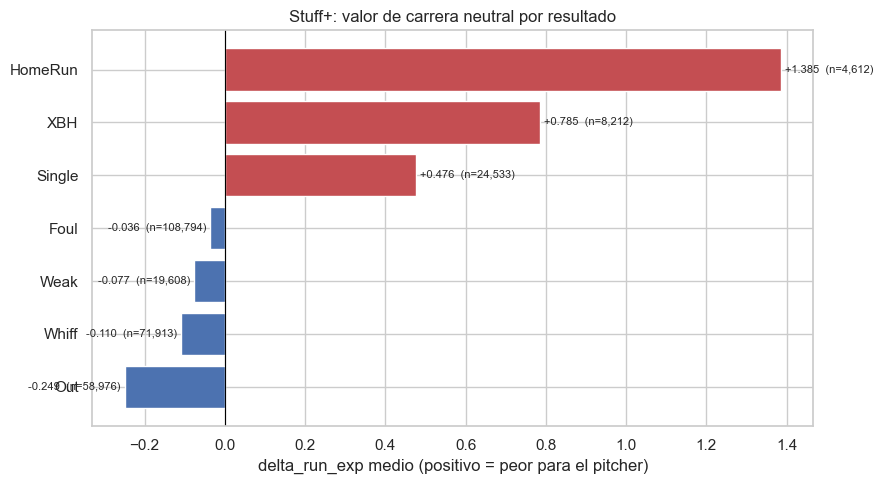

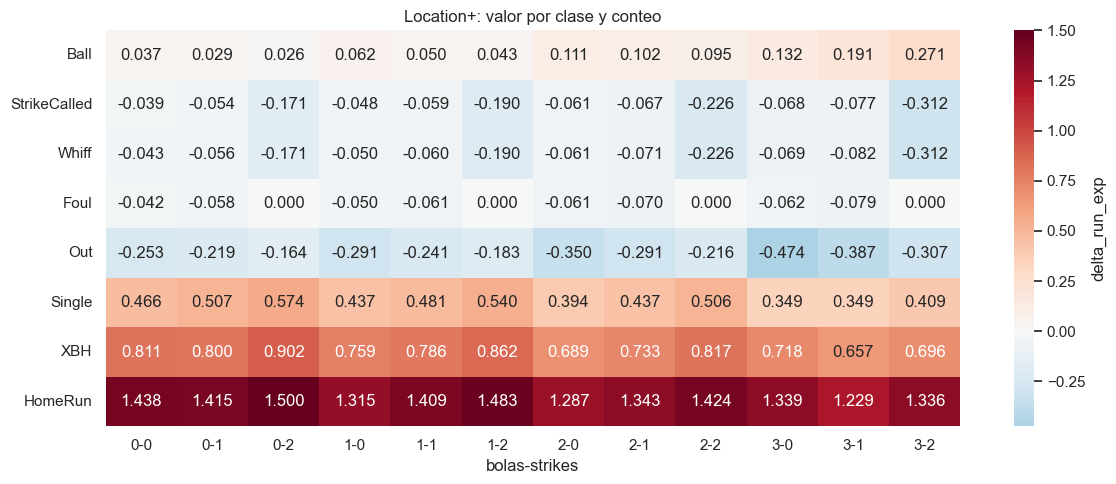

,n,run_value_neutral
loc_class,,
Ball,239691,0.061
StrikeCalled,97809,-0.059
Whiff,71913,-0.110
Foul,108794,-0.036
Out,74241,-0.248
Single,28579,0.477
XBH,8505,0.785
HomeRun,4616,1.385


In [72]:
_BASE_MAP = {"StrikeSwinging": "Whiff", "FoulBall": "Foul", "Out": "Out", "Single": "Single", "Double": "XBH",
             "Triple": "XBH", "HomeRun": "HomeRun", "BallCalled": "Ball", "Walk": "Ball", "HitByPitch": "Ball",
             "StrikeCalled": "StrikeCalled"}


def build_labels(df, scheme):
    base = df["event_type"].map(_BASE_MAP).astype(object)
    if scheme == "swing_cq":
        es = pd.to_numeric(df["ExitSpeed"], errors="coerce") if "ExitSpeed" in df.columns else pd.Series(np.nan, index=df.index)
        bip = base.isin(["Out", "Single", "XBH", "HomeRun"])
        lab = base.where(~(bip & (es < WEAK_EV)), "Weak")
        return lab.where(lab.isin(STUFF_CLASSES))
    if scheme == "all8":
        return base.where(base.isin(LOC_CLASSES))
    raise ValueError(scheme)


def class_run_values(df, labels, classes):
    """(valor neutral (K,), valor por conteo (K,4,3)) a partir de delta_run_exp."""
    m = labels.notna() & df["has_rv"]
    sub = df.loc[m, ["delta_run_exp", "Balls", "Strikes"]].assign(c=labels[m])
    neutral = sub.groupby("c")["delta_run_exp"].mean().reindex(classes).fillna(0.0).to_numpy()
    arr = np.tile(neutral[:, None, None], (1, 4, 3))
    for (c, b, s), v in sub.groupby(["c", "Balls", "Strikes"])["delta_run_exp"].mean().items():
        if 0 <= b <= 3 and 0 <= s <= 2:
            arr[classes.index(c), int(b), int(s)] = v
    return neutral, arr


def rv_by_count(balls, strikes, arr, neutral):
    b = pd.to_numeric(pd.Series(np.asarray(balls)), errors="coerce")
    s = pd.to_numeric(pd.Series(np.asarray(strikes)), errors="coerce")
    bad = (b.isna() | s.isna() | (b < 0) | (b > 3) | (s < 0) | (s > 2)).to_numpy()
    M = arr[:, b.fillna(0).clip(0, 3).astype(int).to_numpy(), s.fillna(0).clip(0, 2).astype(int).to_numpy()].T.copy()
    M[bad] = neutral
    return M


df["stuff_class"] = build_labels(df, "swing_cq")
df["loc_class"] = build_labels(df, "all8")
STUFF_RV_NEUTRAL, _ = class_run_values(df, df["stuff_class"], STUFF_CLASSES)
LOC_RV_NEUTRAL, LOC_RV_ARR = class_run_values(df, df["loc_class"], LOC_CLASSES)
print("Valor de carrera por clase — Stuff+ (swing_cq, neutral):")
display(pd.Series(STUFF_RV_NEUTRAL, index=STUFF_CLASSES, name="run_value").round(3).to_frame().T)
print("Valor de carrera por clase — Location+ (all8, neutral; el modelo usa el valor por conteo):")
display(pd.Series(LOC_RV_NEUTRAL, index=LOC_CLASSES, name="run_value").round(3).to_frame().T)

# Visualización rápida: impacto medio de cada resultado y efecto del conteo.
stuff_counts = (df.loc[df["stuff_class"].notna() & df["has_rv"], "stuff_class"]
                  .value_counts().reindex(STUFF_CLASSES).fillna(0).astype(int))
loc_counts = (df.loc[df["loc_class"].notna() & df["has_rv"], "loc_class"]
                .value_counts().reindex(LOC_CLASSES).fillna(0).astype(int))

stuff_plot = pd.DataFrame({"run_value": STUFF_RV_NEUTRAL, "n": stuff_counts.to_numpy()},
                          index=STUFF_CLASSES).sort_values("run_value")
colors = np.where(stuff_plot["run_value"] > 0, "#C44E52", "#4C72B0")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(stuff_plot.index, stuff_plot["run_value"], color=colors)
for y, (value, n) in enumerate(zip(stuff_plot["run_value"], stuff_plot["n"])):
    ax.text(value + (0.01 if value >= 0 else -0.01), y, f"{value:+.3f}  (n={n:,})",
            va="center", ha="left" if value >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=.8)
ax.set(title="Stuff+: valor de carrera neutral por resultado",
       xlabel="delta_run_exp medio (positivo = peor para el pitcher)")
display(stuff_plot.rename(columns={"run_value": "run_value_neutral"}).round(3))
savefig("05a_valor_carrera_stuff")

loc_heat = pd.DataFrame(
    LOC_RV_ARR.reshape(len(LOC_CLASSES), -1),
    index=LOC_CLASSES,
    columns=[f"{b}-{s}" for b in range(4) for s in range(3)],
)
fig, ax = plt.subplots(figsize=(12, 5))
if sns is not None:
    sns.heatmap(loc_heat, annot=True, fmt=".3f", center=0, cmap="RdBu_r", ax=ax,
                cbar_kws={"label": "delta_run_exp"})
else:
    image = ax.imshow(loc_heat.to_numpy(), aspect="auto", cmap="RdBu_r",
                      vmin=-np.nanmax(np.abs(loc_heat)), vmax=np.nanmax(np.abs(loc_heat)))
    ax.set_xticks(range(len(loc_heat.columns)), loc_heat.columns)
    ax.set_yticks(range(len(loc_heat.index)), loc_heat.index)
    for i in range(len(loc_heat.index)):
        for j in range(len(loc_heat.columns)):
            ax.text(j, i, f"{loc_heat.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7)
    fig.colorbar(image, ax=ax, label="delta_run_exp")
ax.set(title="Location+: valor por clase y conteo", xlabel="bolas-strikes", ylabel="")
savefig("05b_valor_carrera_location")

display(pd.DataFrame({"n": loc_counts, "run_value_neutral": LOC_RV_NEUTRAL}).round(3))


## 6. Modelos publicados: carga del manifest y de los boosters
- Se cargan exactamente los artefactos portables de `artifacts/models`.
- Cada tipo tiene cinco boosters de folds; sus predicciones se conservan como cinco draws.
- Este notebook no usa `oof.parquet` para sustituir los scores. OOF pertenece
  a corridas históricas; el deploy lee `mockup_data.json`, generado por
  `analysis/evidence.py --model`, con el modelo publicado.
- El Stuff+ se puntúa **neutral a la lateralidad** (promedia `same_hand = 0/1` con el peso observado) y se normaliza por
  tipo de pitcheo: `100 − 10·z(xRV)`. Mayor es mejor; 10 puntos = 1 desviación estándar de pitcheos del tipo.
- Los scores del notebook salen exclusivamente de los modelos publicados.
  Los OOF históricos no se mezclan con las gráficas ni con los rankings.


In [73]:
def _predict(bst, X):
    return bst.predict(xgb.DMatrix(X)).reshape(len(X), -1)


def trained_types(df, labels):
    mask = labels.notna() & df["has_rv"] & df["valid_hand"]
    return [p for p, n in df.loc[mask, PT].value_counts().items() if p not in EXCLUDE_PITCH_TYPES and n >= MIN_ROWS_PER_TYPE]


def load_portable_model(model_dir):
    """Carga un modelo publicado y conserva todos sus boosters de validación cruzada."""
    manifest_path = os.path.join(model_dir, "manifest.json")
    if not os.path.isfile(manifest_path):
        raise FileNotFoundError(f"No existe el manifest publicado: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    boosters = {}
    for pt, names in manifest["run"]["boosters"].items():
        loaded = []
        for name in names:
            path = os.path.join(model_dir, name)
            if not os.path.isfile(path):
                raise FileNotFoundError(f"Falta el booster publicado: {path}")
            bst = xgb.Booster()
            bst.load_model(path)
            loaded.append(bst)
        if len(loaded) < 2:
            raise ValueError(f"{model_dir}: {pt} no tiene suficientes boosters para una banda")
        boosters[pt] = loaded
    return manifest, boosters


STUFF_MANIFEST, STUFF_BOOSTERS = load_portable_model(STUFF_MODEL_DIR)
LOC_MANIFEST, LOC_BOOSTERS = load_portable_model(LOC_MODEL_DIR)
STUFF_MODELS = {pt: models[0] for pt, models in STUFF_BOOSTERS.items()}
LOC_MODELS = {pt: models[0] for pt, models in LOC_BOOSTERS.items()}
STUFF_FEATURES = STUFF_MANIFEST["run"]["features"]
LOC_FEATURES = LOC_MANIFEST["run"]["features"]
STUFF_CLASSES = STUFF_MANIFEST["run"]["classes"]
LOC_CLASSES = LOC_MANIFEST["run"]["classes"]
STUFF_RV_NEUTRAL = np.asarray(STUFF_MANIFEST["run"]["rv_neutral"], dtype=float)
LOC_RV_NEUTRAL = np.asarray(LOC_MANIFEST["run"]["rv_neutral"], dtype=float)
LOC_RV_ARR = np.asarray(LOC_MANIFEST["rv_by_count"], dtype=float)
P_SAME = {k: float(v) for k, v in STUFF_MANIFEST["p_same"].items()}
STUFF_MU_SD = {k: tuple(v) for k, v in STUFF_MANIFEST["scale"]["by_type"].items()}
LOC_MU_SD = {k: tuple(v) for k, v in LOC_MANIFEST["scale"].items()}
STUFF_CLIP = STUFF_MANIFEST["clip"]
print(f"Stuff+ publicado: {STUFF_MANIFEST['model_id']} | {len(STUFF_BOOSTERS)} tipos × 5 boosters")
print(f"Location+ publicado: {LOC_MANIFEST['model_id']} | {len(LOC_BOOSTERS)} tipos × 5 boosters")


stuff_rows = df["valid_hand"] & df[STUFF_CORE].notna().all(axis=1)
loc_rows = df["valid_hand"] & df[["PlateLocHeight", "PlateLocSide", "Balls", "Strikes"]].notna().all(axis=1)


Stuff+ publicado: 1.1.0+19966f3 | 6 tipos × 5 boosters
Location+ publicado: 1.0.0+19966f3 | 6 tipos × 5 boosters


In [74]:
def feature_list(bst, default):
    return list(bst.feature_names) if bst.feature_names else list(default)


def clip_stuff_features(X, pt):
    """Aplica los cuantiles publicados por tipo, igual que FinalStuffScorer."""
    X = X.copy()
    for col, bounds in STUFF_CLIP[pt].items():
        if col in X.columns:
            X[col] = X[col].clip(float(bounds[0]), float(bounds[1]))
    return X


def p_same_by_type(df, models):
    """Peso de same_hand=1 (proporción observada por tipo en las filas de entrenamiento)."""
    m = stuff_rows & df["stuff_class"].notna() & df["has_rv"]
    return {pt: float(df.loc[m & (df[PT] == pt), "same_hand"].mean()) for pt in models}


def score_xrv_stuff(df, models, rv_neutral, p_same):
    """xRV neutral a la mano cuando el booster lo requiere.

    El Stuff+ monotónico publicado ya destiló la mano del bateador y por eso
    sus boosters tienen 12 features, sin ``same_hand``. El Stuff+ multiclase
    anterior sí tenía esa columna y conserva el promedio ponderado.
    """
    xrv = pd.Series(np.nan, index=df.index)
    arsenal_key = [GROUP_COL, "year", ALT]
    base = (df["valid_hand"] & df[STUFF_CORE].notna().all(axis=1)
            & df[arsenal_key].notna().all(axis=1))
    for pt, model_list in models.items():
        m = base & (df[PT] == pt)
        if not m.any():
            continue
        draws = []
        for bst in model_list:
            X = df.loc[m, feature_list(bst, STUFF_FEATURES)].astype("float32")
            X = clip_stuff_features(X, pt)
            feats = feature_list(bst, STUFF_FEATURES)
            if "same_hand" in feats:
                p0 = _predict(bst, X.assign(same_hand=0.0))
                p1 = _predict(bst, X.assign(same_hand=1.0))
                P = (1 - p_same[pt]) * p0 + p_same[pt] * p1
                draws.append(P @ rv_neutral)
            else:
                draws.append(_predict(bst, X).reshape(-1))
        xrv[m] = np.mean(draws, axis=0)
    return xrv


def score_xrv_stuff_official(df):
    """Puntúa Stuff+ con la misma implementación que usa el deploy."""
    package_root = os.path.abspath(
        os.path.join("superestela", "superestela", "packages")
    )
    if package_root not in sys.path:
        sys.path.insert(0, package_root)
    from models.portable import load

    scorer = load(STUFF_MODEL_DIR)
    frame = pd.DataFrame({
        "pitch_type": df[PT],
        "pitcher_hand": df["PitcherThrows"],
        "release_speed": df["RelSpeed"],
        "spin_rate": df["SpinRate"],
        "spin_axis": np.where(
            df["PitcherThrows"].eq("Left"),
            (360.0 - df["SpinAxis"]) % 360.0,
            df["SpinAxis"],
        ),
        "ivb": df["InducedVertBreak"],
        "horizontal_break": df["HorzBreak_m"],
        "release_height": df["RelHeight"],
        "release_side": df["RelSide_m"],
        "extension": df["Extension"],
        "speed_diff": df["speed_diff_env"],
        "ivb_diff": df["ivb_diff_env"],
        "hb_diff": df["hb_diff_env"],
    }, index=df.index)
    base = (df["valid_hand"] & frame["pitch_type"].isin(scorer.pitch_types)
            & frame[["release_speed", "spin_rate", "spin_axis", "ivb",
                     "horizontal_break", "release_height", "release_side",
                     "extension", "speed_diff", "ivb_diff", "hb_diff"]].notna().all(axis=1))
    out = pd.Series(np.nan, index=df.index, dtype=float)
    for pt in scorer.pitch_types:
        m = base & (frame["pitch_type"] == pt)
        if m.any():
            out.loc[m] = scorer.stuff_plus(frame.loc[m]).mean(axis=0)
    return out


def score_xrv_location(df, models, rv_arr, rv_neutral):
    xrv = pd.Series(np.nan, index=df.index)
    base = df["valid_hand"] & df[["PlateLocHeight", "PlateLocSide", "Balls", "Strikes"]].notna().all(axis=1)
    for pt, model_list in models.items():
        m = base & (df[PT] == pt)
        if not m.any():
            continue
        sub = df.loc[m]
        draws = []
        for bst in model_list:
            P = _predict(bst, sub[feature_list(bst, LOC_FEATURES)].astype("float32"))
            draws.append((P * rv_by_count(sub["Balls"], sub["Strikes"], rv_arr, rv_neutral)).sum(1))
        xrv[m] = np.mean(draws, axis=0)
    return xrv


def to_plus(xrv, types, mu_sd):
    """Escala 100 ± 10: 100 − 10·(xRV − media_tipo)/sd_tipo."""
    mu = types.map({k: v[0] for k, v in mu_sd.items()})
    sd = types.map({k: v[1] for k, v in mu_sd.items()})
    return 100 - 10 * (xrv - mu) / sd


df["Stuff_Plus_final"] = score_xrv_stuff_official(df)
df["xrv_loc_final"] = score_xrv_location(df, LOC_BOOSTERS, LOC_RV_ARR, LOC_RV_NEUTRAL)
print("Normalización Stuff+ y Location+ desde los manifests publicados (fuera de fold).")

df["xrv_stuff_final"] = np.nan
for pt, (mu, sd) in STUFF_MU_SD.items():
    m = df[PT].eq(pt) & df["Stuff_Plus_final"].notna()
    df.loc[m, "xrv_stuff_final"] = mu + sd * (100 - df.loc[m, "Stuff_Plus_final"]) / 10
df["Location_Plus_final"] = to_plus(df["xrv_loc_final"], df[PT], LOC_MU_SD)


df["Stuff_Plus"], df["xrv_stuff"] = df["Stuff_Plus_final"], df["xrv_stuff_final"]
df["Location_Plus"], df["xrv_loc"] = df["Location_Plus_final"], df["xrv_loc_final"]
SCORE_SOURCE_S = "modelo publicado: artifacts/models/stuff_plus_final_v1_monotone"
SCORE_SOURCE_L = "modelo publicado: artifacts/models/location_plus_l3"
print("Fuente Stuff+:", SCORE_SOURCE_S, "| Fuente Location+:", SCORE_SOURCE_L)


print(f"Pitcheos con Stuff+: {int(df['Stuff_Plus'].notna().sum()):,} | con Location+: {int(df['Location_Plus'].notna().sum()):,}")
display(df.groupby(PT)[["Stuff_Plus", "Location_Plus"]].agg(["count", "mean", "std"]).round(2))

# Comparación opcional contra lo que realmente lee el deploy.
# `mockup_data.json` contiene tarjetas agregadas y no reemplaza el score de pitch.
MOCKUP_PATH = os.path.join("superestela", "superestela", "analysis", "outputs", "mockup_data.json")
if os.path.exists(MOCKUP_PATH):
    with open(MOCKUP_PATH, encoding="utf-8") as fh:
        deploy_cards = pd.DataFrame(json.load(fh).get("pitchers", []))
    deploy_cards = deploy_cards.rename(columns={"pitcher_id": GROUP_COL, "season": "year"})
    notebook_cards = (df[df["Stuff_Plus"].notna()]
                      .groupby([GROUP_COL, "year", ALT])["Stuff_Plus"].mean()
                      .unstack(ALT)
                      .rename(columns={"Extreme Altitude": "notebook_hh", "No Altitude": "notebook_sea"})
                      .reset_index())
    deploy_check = deploy_cards[[GROUP_COL, "year", "stuff_plus_hh", "stuff_plus_sea"]].merge(
        notebook_cards[[GROUP_COL, "year", "notebook_hh", "notebook_sea"]],
        on=[GROUP_COL, "year"], how="left",
    )
    deploy_check["diff_hh"] = deploy_check["notebook_hh"] - deploy_check["stuff_plus_hh"]
    deploy_check["diff_sea"] = deploy_check["notebook_sea"] - deploy_check["stuff_plus_sea"]
    print("Comparación contra analysis/outputs/mockup_data.json (tarjetas del deploy):")
    display(deploy_check[["diff_hh", "diff_sea"]].describe().round(2))

# Constantes para puntuar datos nuevos sin recalcular nada
META = {"stuff_classes": STUFF_CLASSES, "stuff_features": STUFF_FEATURES, "stuff_rv_neutral": STUFF_RV_NEUTRAL.tolist(),
        "p_same": P_SAME, "stuff_mu_sd": {k: list(v) for k, v in STUFF_MU_SD.items()},
        "loc_classes": LOC_CLASSES, "loc_features": LOC_FEATURES, "loc_rv_neutral": LOC_RV_NEUTRAL.tolist(),
        "loc_rv_arr": LOC_RV_ARR.tolist(), "loc_mu_sd": {k: list(v) for k, v in LOC_MU_SD.items()},
        "stuff_model_dir": STUFF_MODEL_DIR, "loc_model_dir": LOC_MODEL_DIR,
        "stuff_model_id": STUFF_MANIFEST["model_id"], "loc_model_id": LOC_MANIFEST["model_id"]}
os.makedirs(os.path.dirname(META_PATH) or ".", exist_ok=True)
json.dump(META, open(META_PATH, "w"), indent=1)


Normalización Stuff+ y Location+ desde los manifests publicados (fuera de fold).
Fuente Stuff+: modelo publicado: artifacts/models/stuff_plus_final_v1_monotone | Fuente Location+: modelo publicado: artifacts/models/location_plus_l3
Pitcheos con Stuff+: 619,388 | con Location+: 625,345


Stuff_Plus               Location_Plus              
                     count    mean   std         count    mean   std
AutoPitchType                                                       
Changeup             77753   99.76  9.66         78509   99.99  9.90
Curveball            53264  100.17  9.44         53828  100.01  9.89
Cutter               26069  100.35  9.01         26386  100.02  9.86
Four-Seam           215225  100.11  9.82        217096  100.00  9.97
Knuckleball              0     NaN   NaN             0     NaN   NaN
OneSeamFastBall          0     NaN   NaN             0     NaN   NaN
Other                    0     NaN   NaN             0     NaN   NaN
Sinker              109514  100.12  9.41        110654  100.02  9.92
Slider              137563  100.02  9.80        138872   99.99  9.94
Splitter                 0     NaN   NaN             0     NaN   NaN
Sweeper                  0     NaN   NaN             0     NaN   NaN
TwoSeamFastBall          0     NaN   NaN             0     NaN   NaN

Comparación contra analysis/outputs/mockup_data.json (tarjetas del deploy):


,diff_hh,diff_sea
count,709.00,710.00
mean,-0.00,0.00
std,0.03,0.04
min,-0.10,-0.19
25%,-0.03,-0.03
50%,-0.00,-0.00
75%,0.03,0.02
max,0.05,0.65


## 7. Validación
1. **Calibración:** deciles de xRV contra el run value observado (solo swings).
2. **Persistencia 2023→2024:** ¿el Stuff+ de un lanzador/tipo conserva su orden entre temporadas?
3. **Validez:** ¿se parece a whiff por swing?

La comparación 2023→2024 es una prueba de persistencia, no una predicción
perfecta: un pitch puede cambiar por velocidad, movimiento, salud o arsenal.


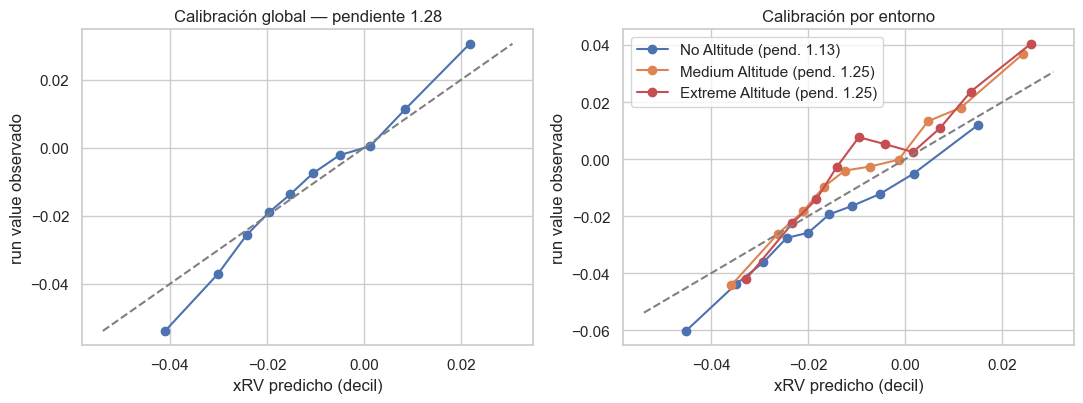

In [75]:
def decile_calibration(d, xrv_col, n=10):
    t = d[[xrv_col, "delta_run_exp"]].dropna()
    t["bin"] = pd.qcut(t[xrv_col], n, labels=False, duplicates="drop")
    g = t.groupby("bin").agg(xrv=(xrv_col, "mean"), real=("delta_run_exp", "mean"), n=(xrv_col, "size"))
    return g, float(np.polyfit(g["xrv"], g["real"], 1)[0])


sw = df[df["is_swing"] & df["has_rv"] & df["xrv_stuff"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
g, slope = decile_calibration(sw, "xrv_stuff")
axes[0].plot(g["xrv"], g["real"], "o-")
lo, hi = min(g["xrv"].min(), g["real"].min()), max(g["xrv"].max(), g["real"].max())
axes[0].plot([lo, hi], [lo, hi], "--", color="gray")
axes[0].set(xlabel="xRV predicho (decil)", ylabel="run value observado", title=f"Calibración global — pendiente {slope:.2f}")
for env, c in zip(["No Altitude", "Medium Altitude", "Extreme Altitude"], ["#4C72B0", "#DD8452", "#C44E52"]):
    s_env = sw[sw[ALT] == env]
    if len(s_env) > 2000:
        g, sl = decile_calibration(s_env, "xrv_stuff")
        axes[1].plot(g["xrv"], g["real"], "o-", color=c, label=f"{env} (pend. {sl:.2f})")
axes[1].plot([lo, hi], [lo, hi], "--", color="gray")
axes[1].set(xlabel="xRV predicho (decil)", ylabel="run value observado", title="Calibración por entorno")
axes[1].legend()
savefig("02_calibracion")


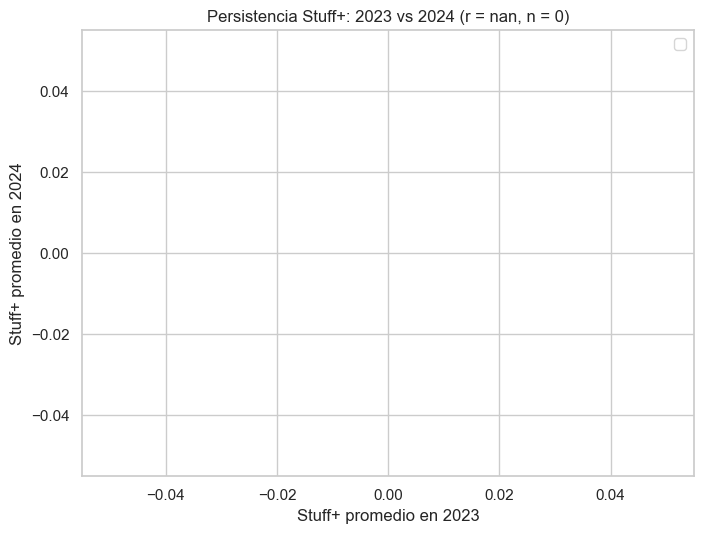

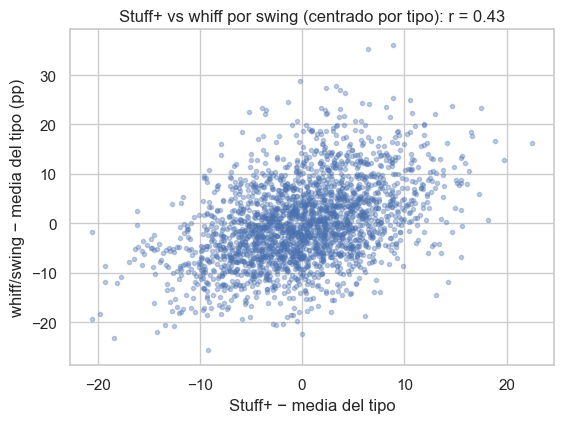

persistencia 2023-2024 r = nan | Stuff+ vs whiff r = 0.43


In [76]:
def pitcher_type_means(d, col):
    return d.groupby([GROUP_COL, PT, "year"]).agg(x=(col, "mean"), n=(col, "size")).reset_index()


# Persistencia anual explícita: temporada 2023 contra temporada 2024.
d = df[df["Stuff_Plus"].notna()].copy()
t = pitcher_type_means(d, "Stuff_Plus")
t = t[t["n"] >= 80]
t23 = t[t["year"] == 2023].rename(columns={"x": "stuff_2023", "n": "n_2023"})
t24 = t[t["year"] == 2024].rename(columns={"x": "stuff_2024", "n": "n_2024"})
m = t23.merge(t24, on=[GROUP_COL, PT], how="inner")
m = m[(m["n_2023"] >= 80) & (m["n_2024"] >= 80)]
r_2023_2024 = np.corrcoef(m["stuff_2023"], m["stuff_2024"])[0, 1] if len(m) > 10 else np.nan

fig, ax = plt.subplots(figsize=(7.2, 5.5))
ax.scatter(m["stuff_2023"], m["stuff_2024"], s=16, alpha=.45, color="#55A868")
if len(m):
    lo = min(m["stuff_2023"].min(), m["stuff_2024"].min())
    hi = max(m["stuff_2023"].max(), m["stuff_2024"].max())
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1, label="igual en ambos años")
ax.set(title=f"Persistencia Stuff+: 2023 vs 2024 (r = {r_2023_2024:.2f}, n = {len(m)})",
       xlabel="Stuff+ promedio en 2023", ylabel="Stuff+ promedio en 2024")
ax.legend()
savefig("03_persistencia_2023_2024")

# Validez: Stuff+ de un lanzador vs su whiff por swing (misma temporada, mismo tipo)
w = df[df["is_swing"] & df["Stuff_Plus"].notna()].groupby([GROUP_COL, PT, "year"]).agg(
    stuff=("Stuff_Plus", "mean"), whiff=("is_whiff", "mean"), ns=("is_whiff", "size")).reset_index()
w = w[w["ns"] >= 40]
w["stuff_c"] = w["stuff"] - w.groupby(PT)["stuff"].transform("mean")
w["whiff_c"] = w["whiff"] - w.groupby(PT)["whiff"].transform("mean")
r_whiff = np.corrcoef(w["stuff_c"], w["whiff_c"])[0, 1]
fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.scatter(w["stuff_c"], 100 * w["whiff_c"], s=9, alpha=.35)
ax.set(title=f"Stuff+ vs whiff por swing (centrado por tipo): r = {r_whiff:.2f}",
       xlabel="Stuff+ − media del tipo", ylabel="whiff/swing − media del tipo (pp)")
savefig("04_validez_whiff")
print(f"persistencia 2023-2024 r = {r_2023_2024:.2f} | Stuff+ vs whiff r = {r_whiff:.2f}")


## 8. Rankings de lanzadores
Llave **lanzador–temporada**. Mínimo de pitcheos por entorno para entrar (muestra chica = ruido, no talento).
- `stuff_env`: **100 = promedio de ese entorno** (por tipo). Es la escala que responde "¿quién es mejor *en altitud*
  entre los que lanzan ahí?" (la que pidió Diablos).
- `stuff_abs`: escala global (la altitud promedia por debajo de 100 porque la forma se degrada).
- `delta`: Stuff+ en altitud menos nivel del mar (más cercano a 0 = **resiste** la altura).


In [77]:
NAMES = {}
if NAMES_PATH and os.path.exists(NAMES_PATH):
    for line in open(NAMES_PATH, encoding="utf-8"):
        if "," in line:
            nm, pid = line.rsplit(",", 1)
            NAMES[pid.strip()] = nm.strip()
label = lambda pid: f"{NAMES[pid]} ({pid})" if pid in NAMES else pid


def ranking_env(df, env, col="Stuff_Plus", year=None, min_n=50):
    r = df[(df[ALT] == env) & df[col].notna()]
    if year is not None:
        r = r[r["year"] == year]
    r = r.assign(z_env=lambda x: 100 + 10 * (x[col] - x.groupby(PT)[col].transform("mean")) / x.groupby(PT)[col].transform("std"))
    t = r.groupby([GROUP_COL, "year"]).agg(n=(col, "size"), stuff_abs=(col, "mean"), stuff_env=("z_env", "mean")).reset_index()
    t = t[t["n"] >= min_n].copy()
    t["pctl_env"] = (100 * t["stuff_env"].rank(pct=True)).round(1)
    return t

EXTREME, SEA = "Extreme Altitude", "No Altitude"
YEARS = sorted(df["year"].dropna().astype(int).unique())

# Ranking usando todas las temporadas disponibles.
# Cada punto representa lanzador-temporada.
alt_r = ranking_env(df, EXTREME, year=None, min_n=100)
sea_r = ranking_env(df, SEA, year=None, min_n=100)

both = alt_r.merge(
    sea_r,
    on=[GROUP_COL, "year"],
    suffixes=("_alt", "_sea"),
)

both["delta"] = both["stuff_abs_alt"] - both["stuff_abs_sea"]
both["pctl_resistencia"] = (
    100 * both["delta"].rank(pct=True)
).round(1)

print(
    f"== Datos combinados: {YEARS[0]}-{YEARS[-1]} "
    "(cada punto = lanzador-temporada) =="
)
print(f"Temporadas incluidas: {YEARS}")
print(f"Pares con muestra en ambos entornos: {len(both):,}")

print("\n== Mejores en ALTITUD EXTREMA: todas las temporadas ==")
top_alt = (
    alt_r.sort_values("stuff_env", ascending=False)
    .head(15)
    .assign(lanzador=lambda x: x[GROUP_COL].map(label))
)
display(
    top_alt[
        ["lanzador", "year", "n", "stuff_env", "stuff_abs", "pctl_env"]
    ].round(1)
)

print("\n== Mejores a NIVEL DEL MAR: todas las temporadas ==")
top_sea = (
    sea_r.sort_values("stuff_env", ascending=False)
    .head(10)
    .assign(lanzador=lambda x: x[GROUP_COL].map(label))
)
display(
    top_sea[
        ["lanzador", "year", "n", "stuff_env", "stuff_abs"]
    ].round(1)
)

print("\n== Los que MEJOR RESISTEN la altura: todas las temporadas ==")
res_top = (
    both.sort_values("delta", ascending=False)
    .head(10)
    .assign(lanzador=lambda x: x[GROUP_COL].map(label))
)
display(
    res_top[
        [
            "lanzador",
            "year",
            "stuff_abs_sea",
            "stuff_abs_alt",
            "delta",
            "n_sea",
            "n_alt",
        ]
    ].round(1)
)

print("\n== Sufren en la altura: todas las temporadas ==")
thr_s = both["stuff_abs_sea"].quantile(0.70)
thr_d = both["delta"].quantile(0.30)

sufre = both[
    (both["stuff_abs_sea"] >= thr_s)
    & (both["delta"] <= thr_d)
].assign(lanzador=lambda x: x[GROUP_COL].map(label))

display(
    sufre.sort_values("delta")[
        [
            "lanzador",
            "year",
            "stuff_abs_sea",
            "stuff_abs_alt",
            "delta",
        ]
    ]
    .head(10)
    .round(1)
)

top_alt.to_csv(
    os.path.join(OUT_DIR, "ranking_altitud_extrema_todas_temporadas.csv"),
    index=False,
)


elite = both[
    (both["stuff_abs_sea"] >= 110)
    & (both["stuff_abs_alt"] >= 100)
    & (both["delta"] > -9)
].copy()

elite = elite.sort_values(
    ["stuff_abs_sea", "stuff_abs_alt"],
    ascending=[False, False],
)

elite = elite.assign(
    lanzador=lambda x: x[GROUP_COL].map(label)
)

display(
    elite[
        [
            "lanzador",
            "year",
            "stuff_abs_sea",
            "stuff_abs_alt",
            "delta",
            "n_sea",
            "n_alt",
        ]
    ].round(1)
)

== Datos combinados: 2024-2026 (cada punto = lanzador-temporada) ==
Temporadas incluidas: [np.int64(2024), np.int64(2025), np.int64(2026)]
Pares con muestra en ambos entornos: 369

== Mejores en ALTITUD EXTREMA: todas las temporadas ==


,lanzador,year,n,stuff_env,stuff_abs,pctl_env
1045,pitcher_00890,2025,167,111.3,105.2,100.0
1115,pitcher_00952,2024,550,111.1,105.6,99.8
152,pitcher_00138,2024,469,110.9,105.3,99.6
733,pitcher_00624,2024,187,109.9,104.4,99.5
724,pitcher_00619,2024,853,109.8,104.9,99.3
1307,pitcher_01101,2024,338,109.8,103.8,99.1
1099,pitcher_00939,2024,112,109.7,103.5,98.9
801,pitcher_00685,2026,211,109.6,104.7,98.7
675,pitcher_00566,2025,105,109.6,104.6,98.5
1012,pitcher_00856,2025,104,109.3,103.4,98.4



== Mejores a NIVEL DEL MAR: todas las temporadas ==


,lanzador,year,n,stuff_env,stuff_abs
579,pitcher_00469,2026,208,113.6,116.4
573,pitcher_00465,2026,260,112.4,115.1
123,pitcher_00107,2026,175,111.9,114.8
422,pitcher_00342,2024,153,111.9,115.3
284,pitcher_00234,2026,319,111.2,114.2
1017,pitcher_00829,2025,104,111.1,113.7
134,pitcher_00118,2026,101,111.0,114.1
273,pitcher_00225,2026,158,111.0,113.5
1335,pitcher_01078,2026,320,110.7,113.9
1367,pitcher_01103,2026,252,110.2,113.6



== Los que MEJOR RESISTEN la altura: todas las temporadas ==


,lanzador,year,stuff_abs_sea,stuff_abs_alt,delta,n_sea,n_alt
259,pitcher_00778,2024,83.0,84.5,1.5,629,480
150,pitcher_00430,2024,95.9,97.2,1.4,349,344
129,pitcher_00361,2024,97.4,97.7,0.3,136,297
244,pitcher_00743,2025,102.5,102.7,0.2,364,230
201,pitcher_00604,2025,96.7,96.2,-0.5,113,440
320,pitcher_01003,2025,100.5,99.9,-0.5,172,100
146,pitcher_00418,2025,99.5,98.1,-1.4,131,374
130,pitcher_00361,2026,98.4,96.6,-1.9,163,467
163,pitcher_00464,2024,96.5,94.5,-2.0,1101,197
19,pitcher_00072,2024,94.5,92.5,-2.0,165,913



== Sufren en la altura: todas las temporadas ==


,lanzador,year,stuff_abs_sea,stuff_abs_alt,delta
340,pitcher_01044,2025,109.8,94.9,-14.9
46,pitcher_00141,2025,107.7,93.0,-14.7
162,pitcher_00462,2025,109.5,95.5,-14.1
3,pitcher_00019,2026,113.0,99.0,-14.0
87,pitcher_00236,2025,110.4,96.5,-13.9
35,pitcher_00125,2024,108.1,94.4,-13.7
24,pitcher_00096,2025,112.7,99.2,-13.5
11,pitcher_00047,2026,111.1,97.8,-13.3
17,pitcher_00069,2025,110.8,97.7,-13.0
15,pitcher_00056,2025,108.1,95.1,-13.0


,lanzador,year,stuff_abs_sea,stuff_abs_alt,delta,n_sea,n_alt
305,pitcher_00952,2024,113.5,105.6,-7.9,234,550
208,pitcher_00619,2024,113.0,104.9,-8.0,299,853
43,pitcher_00138,2024,113.0,105.3,-7.7,163,469
287,pitcher_00890,2025,112.3,105.2,-7.1,112,167
156,pitcher_00449,2024,111.9,103.5,-8.4,407,116
190,pitcher_00562,2024,111.7,103.1,-8.7,149,499
316,pitcher_00997,2026,111.5,104.0,-7.5,260,161
211,pitcher_00624,2024,111.1,104.4,-6.7,237,187
225,pitcher_00685,2026,111.0,104.7,-6.4,108,211
353,pitcher_01101,2024,110.8,103.8,-7.0,185,338


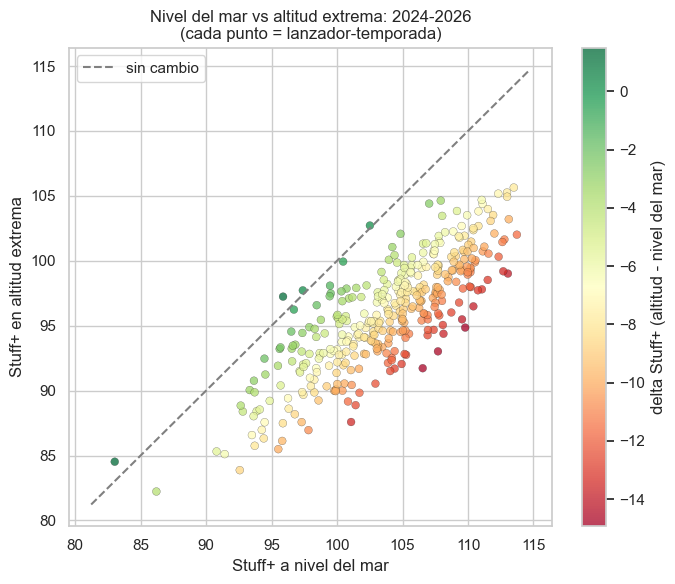

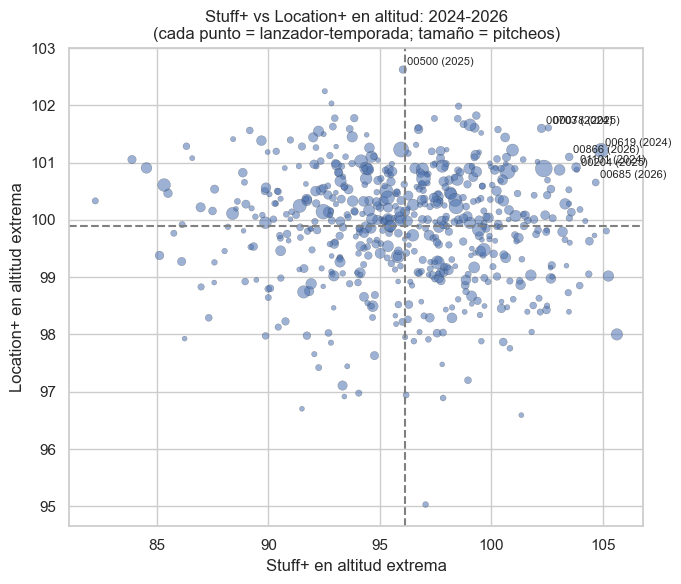

In [78]:

# ------------------------------------------------------------------
# 1. Mapa de reclutamiento: nivel del mar vs altitud
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(both["stuff_abs_sea"],both["stuff_abs_alt"],c=both["delta"],cmap="RdYlGn",
    s=32,
    edgecolor="k",
    linewidth=0.2,
    alpha=0.75,
)

lims = [
    min(
        both["stuff_abs_sea"].min(),
        both["stuff_abs_alt"].min(),
    ) - 1,
    max(
        both["stuff_abs_sea"].max(),
        both["stuff_abs_alt"].max(),
    ) + 1,
]

ax.plot(lims, lims, "--", color="gray", label="sin cambio")

# for _, row in (
#     both.sort_values("stuff_abs_alt", ascending=False)
#     .head(5)
#     .iterrows()
# ):
#     ax.annotate(
#         f"{row[GROUP_COL][-5:]} ({int(row['year'])})",
#         (row["stuff_abs_sea"], row["stuff_abs_alt"]),
#         fontsize=8,
#         xytext=(3, 3),
#         textcoords="offset points",
#     )

plt.colorbar(
    sc,
    label="delta Stuff+ (altitud - nivel del mar)",
)

ax.set(
    xlabel="Stuff+ a nivel del mar",
    ylabel="Stuff+ en altitud extrema",
    title=(
        f"Nivel del mar vs altitud extrema: {YEARS[0]}-{YEARS[-1]}\n"
        "(cada punto = lanzador-temporada)"
    ),
)

ax.legend(loc="upper left")
savefig("05_mar_vs_altitud_todas_temporadas")

# ------------------------------------------------------------------
# 2. Stuff+ vs Location+ en altitud extrema
# ------------------------------------------------------------------
pl = (
    df[df[ALT] == EXTREME]
    .groupby([GROUP_COL, "year"])
    .agg(
        n=("Stuff_Plus", "size"),
        stuff=("Stuff_Plus", "mean"),
        loc=("Location_Plus", "mean"),
    )
    .reset_index()
)

pl = pl[pl["n"] >= 100].dropna()

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    pl["stuff"],
    pl["loc"],
    s=pl["n"] / 8,
    alpha=0.55,
    edgecolor="k",
    linewidth=0.2,
)

ax.axvline(pl["stuff"].mean(), color="gray", ls="--")
ax.axhline(pl["loc"].mean(), color="gray", ls="--")

pl = pl.assign(
    score=(
        (pl["stuff"] - pl["stuff"].mean()) / pl["stuff"].std()
        + (pl["loc"] - pl["loc"].mean()) / pl["loc"].std()
    )
)

for _, row in pl.sort_values("score", ascending=False).head(8).iterrows():
    ax.annotate(
        f"{row[GROUP_COL][-5:]} ({int(row['year'])})",
        (row["stuff"], row["loc"]),
        fontsize=8,
        xytext=(3, 3),
        textcoords="offset points",
    )

ax.set(
    xlabel="Stuff+ en altitud extrema",
    ylabel="Location+ en altitud extrema",
    title=(
        f"Stuff+ vs Location+ en altitud: {YEARS[0]}-{YEARS[-1]}\n"
        "(cada punto = lanzador-temporada; tamaño = pitcheos)"
    ),
)

savefig("06_stuff_vs_location_todas_temporadas")

## 9. Lo que aprendió el modelo
1. **Importancia por ganancia** y **SHAP** (qué features mueven las probabilidades).
2. **Sensibilidad:** cuánto cambia el Stuff+ al subir +1 mph, +1″ de IVB, +1″ de HB, +100 rpm o +0.5 ft de extensión.
3. **Mapas:** Stuff+ sobre el plano de movimiento y valor de la ubicación en el plato.


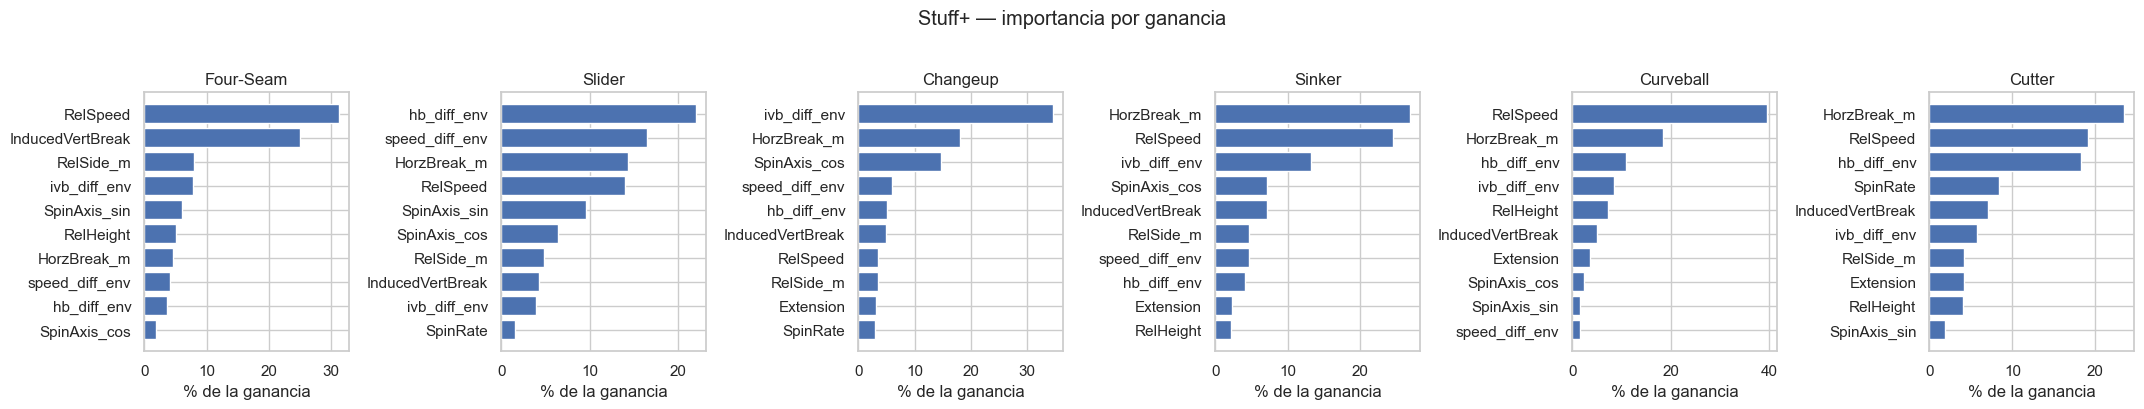

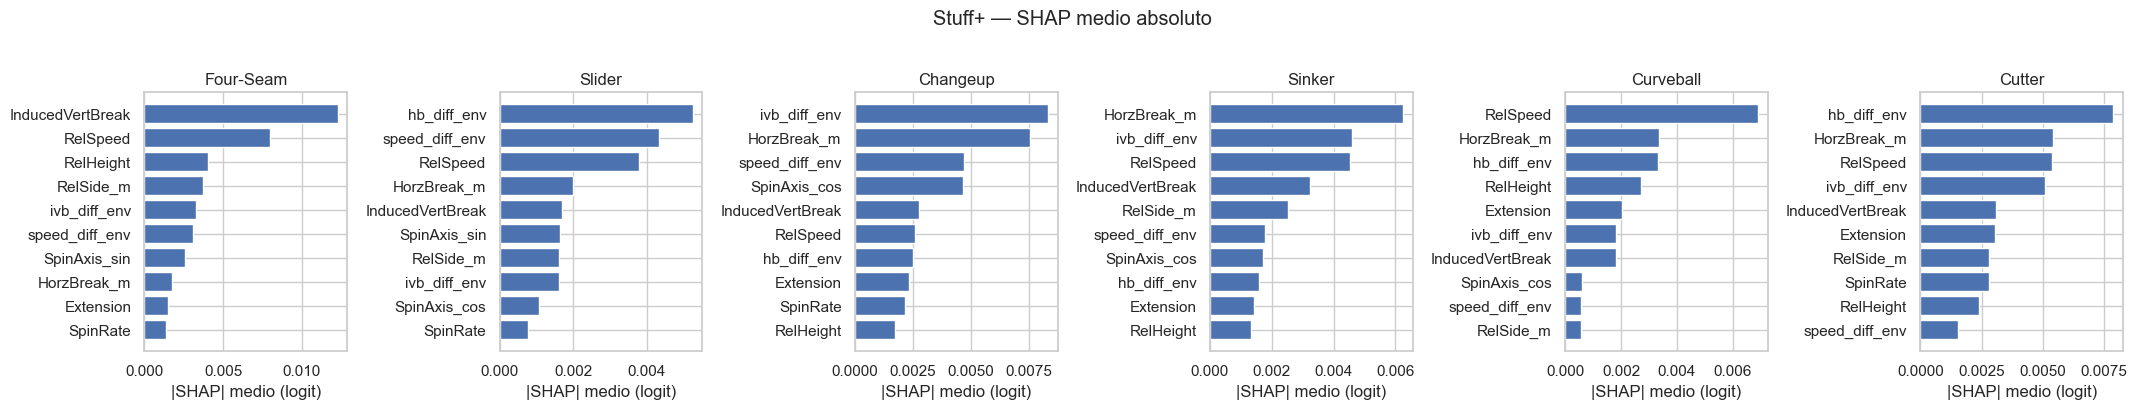

In [79]:
TYPES_S = [p for p in ["Four-Seam", "Slider", "Changeup", "Sinker", "Curveball", "Cutter"] if p in STUFF_MODELS]

# Importancia por ganancia
fig, axes = plt.subplots(1, len(TYPES_S), figsize=(3.6 * len(TYPES_S), 4), squeeze=False)
for ax, pt in zip(axes[0], TYPES_S):
    gain = pd.Series(STUFF_MODELS[pt].get_score(importance_type="gain")).sort_values()
    gain = gain / gain.sum() * 100
    ax.barh(gain.index[-10:], gain.values[-10:])
    ax.set(title=pt, xlabel="% de la ganancia")
fig.suptitle("Stuff+ — importancia por ganancia", y=1.02)
savefig("07_importancia_gain")

# SHAP (valores de contribución de XGBoost, promedio absoluto sobre clases y filas)
fig, axes = plt.subplots(1, len(TYPES_S), figsize=(3.6 * len(TYPES_S), 4), squeeze=False)
shap_tab = {}
rng = np.random.default_rng(0)
for ax, pt in zip(axes[0], TYPES_S):
    bst = STUFF_MODELS[pt]
    feats = feature_list(bst, STUFF_FEATURES)
    pool = df.loc[stuff_rows & (df[PT] == pt), feats].dropna()
    X = pool.iloc[rng.choice(len(pool), min(4000, len(pool)), replace=False)].astype("float32")
    C = bst.predict(xgb.DMatrix(X), pred_contribs=True)
    if C.ndim == 2:
        C = C[:, :-1]
        values = np.abs(C).mean(axis=0)
    else:
        values = np.abs(C[:, :, :-1]).mean(axis=(0, 1))
    s = pd.Series(values, index=feats).sort_values()
    shap_tab[pt] = s
    ax.barh(s.index[-10:], s.values[-10:])
    ax.set(title=pt, xlabel="|SHAP| medio (logit)")
fig.suptitle("Stuff+ — SHAP medio absoluto", y=1.02)
savefig("08_shap")


Cambio medio de Stuff+ (puntos) al mover una feature (las demás fijas; los diferenciales de arsenal no se recalculan):


,+1 mph de velocidad,+1 in de IVB,+1 in de HB (hacia el brazo),+100 rpm,+0.5 ft de extensión
tipo,,,,,
Four-Seam,1.42,2.01,0.14,0.09,-0.16
Slider,1.65,0.46,-0.44,0.13,0.42
Changeup,0.70,0.15,1.10,-0.59,-0.38
Sinker,1.61,0.91,1.56,0.06,0.14
Curveball,2.43,-0.21,-0.37,-0.06,2.01
Cutter,1.33,0.85,-0.81,0.85,1.81


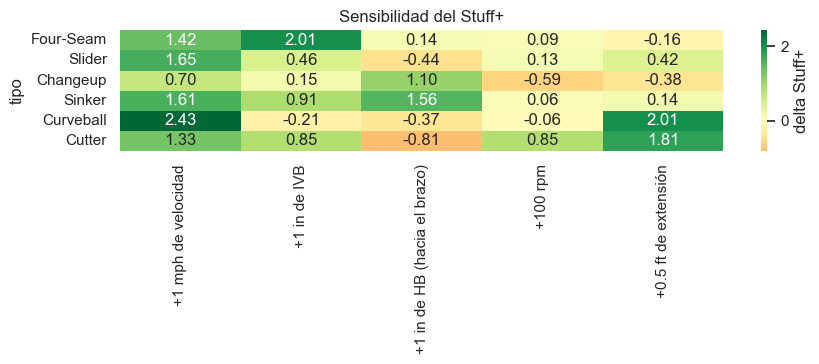

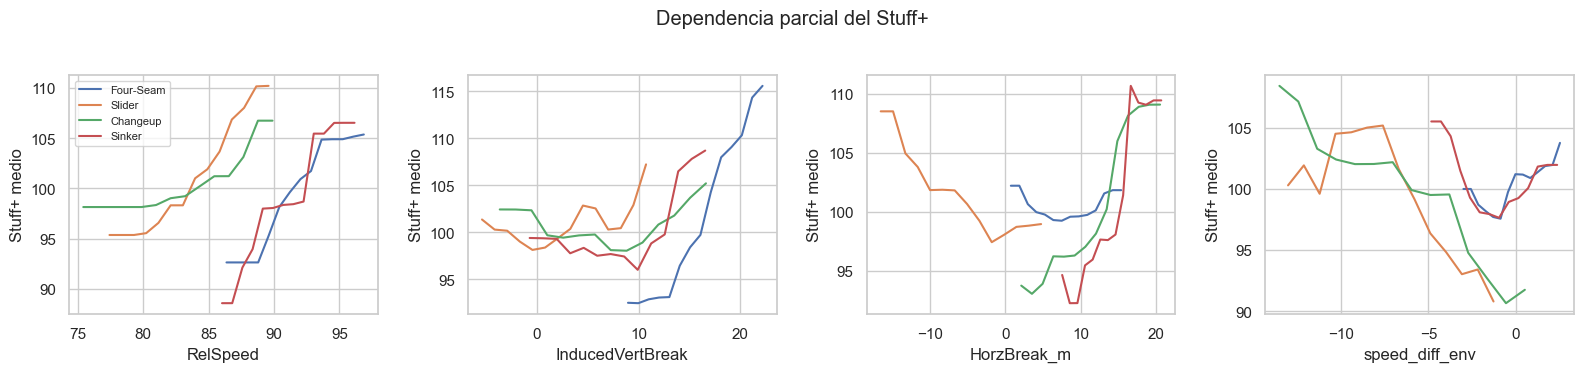

In [80]:
# Sensibilidad: efecto promedio sobre Stuff+ de mover UNA feature, dejando las demás como están
def stuff_from_X(bst, pt, X, rv_neutral=STUFF_RV_NEUTRAL):
    X = clip_stuff_features(X, pt)
    feats = feature_list(bst, STUFF_FEATURES)
    if "same_hand" in feats:
        p = P_SAME[pt]
        P = (1 - p) * _predict(bst, X.assign(same_hand=0.0)) + p * _predict(bst, X.assign(same_hand=1.0))
    else:
        P = _predict(bst, X)
    mu, sd = STUFF_MU_SD[pt]
    xrv = P if len(rv_neutral) != P.shape[1] else P @ rv_neutral
    return 100 - 10 * (xrv - mu) / sd


DELTAS = {"+1 mph de velocidad": ("RelSpeed", 1.0), "+1 in de IVB": ("InducedVertBreak", 1.0), "+1 in de HB (hacia el brazo)": ("HorzBreak_m", 1.0),
          "+100 rpm": ("SpinRate", 100.0), "+0.5 ft de extensión": ("Extension", 0.5)}
rows = []
for pt in TYPES_S:
    bst = STUFF_MODELS[pt]
    feats = feature_list(bst, STUFF_FEATURES)
    pool = df.loc[stuff_rows & (df[PT] == pt), feats].dropna()
    X = pool.iloc[np.random.default_rng(1).choice(len(pool), min(5000, len(pool)), replace=False)].astype("float32")
    base = stuff_from_X(bst, pt, X)
    row = {"tipo": pt}
    for name, (f, dx) in DELTAS.items():
        Xd = X.copy()
        Xd[f] = Xd[f] + dx
        row[name] = float((stuff_from_X(bst, pt, Xd) - base).mean())
    rows.append(row)
sens = pd.DataFrame(rows).set_index("tipo")
print("Cambio medio de Stuff+ (puntos) al mover una feature (las demás fijas; los diferenciales de arsenal no se recalculan):")
display(sens.round(2))
fig, ax = plt.subplots(figsize=(9, 3.8))
if sns is not None:
    sns.heatmap(sens, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax,
                cbar_kws={"label": "delta Stuff+"})
else:
    limit = float(np.nanmax(np.abs(sens.to_numpy())))
    image = ax.imshow(sens.to_numpy(), aspect="auto", cmap="RdYlGn",
                      vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(sens.columns)), sens.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(sens.index)), sens.index)
    for i in range(len(sens.index)):
        for j in range(len(sens.columns)):
            ax.text(j, i, f"{sens.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="delta Stuff+")
ax.set_title("Sensibilidad del Stuff+")
savefig("09_sensibilidad")

# Dependencia parcial de las features principales
pdp_feats = ["RelSpeed", "InducedVertBreak", "HorzBreak_m", "speed_diff_env"]
fig, axes = plt.subplots(1, len(pdp_feats), figsize=(4 * len(pdp_feats), 3.6), squeeze=False)
for ax, f in zip(axes[0], pdp_feats):
    for pt in TYPES_S[:4]:
        bst = STUFF_MODELS[pt]
        feats = feature_list(bst, STUFF_FEATURES)
        pool = df.loc[stuff_rows & (df[PT] == pt), feats].dropna()
        X = pool.iloc[np.random.default_rng(2).choice(len(pool), min(2500, len(pool)), replace=False)].astype("float32")
        grid = np.linspace(pool[f].quantile(.02), pool[f].quantile(.98), 14)
        ax.plot(grid, [stuff_from_X(bst, pt, X.assign(**{f: v})).mean() for v in grid], label=pt)
    ax.set(xlabel=f, ylabel="Stuff+ medio")
axes[0][0].legend(fontsize=8)
fig.suptitle("Dependencia parcial del Stuff+", y=1.03)
savefig("10_dependencia_parcial")


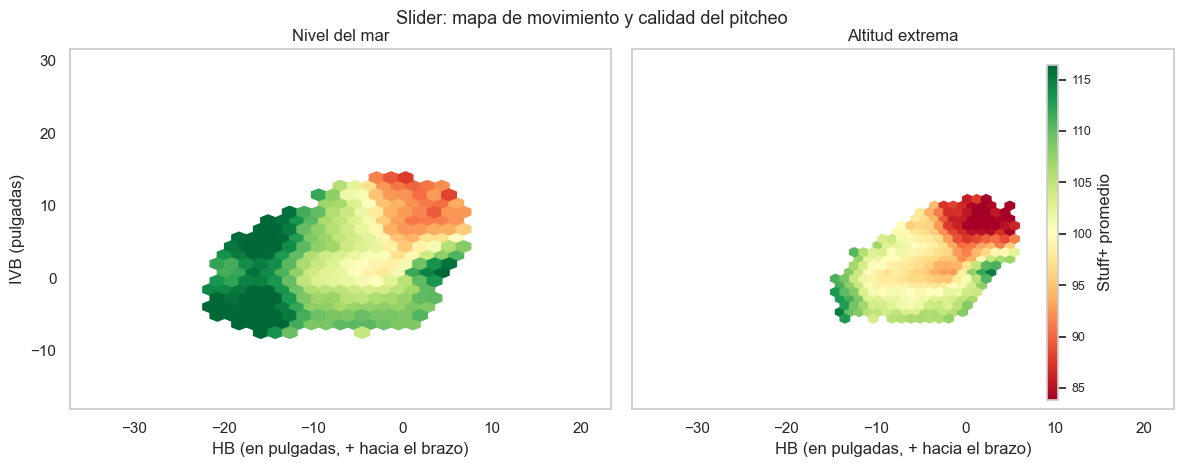

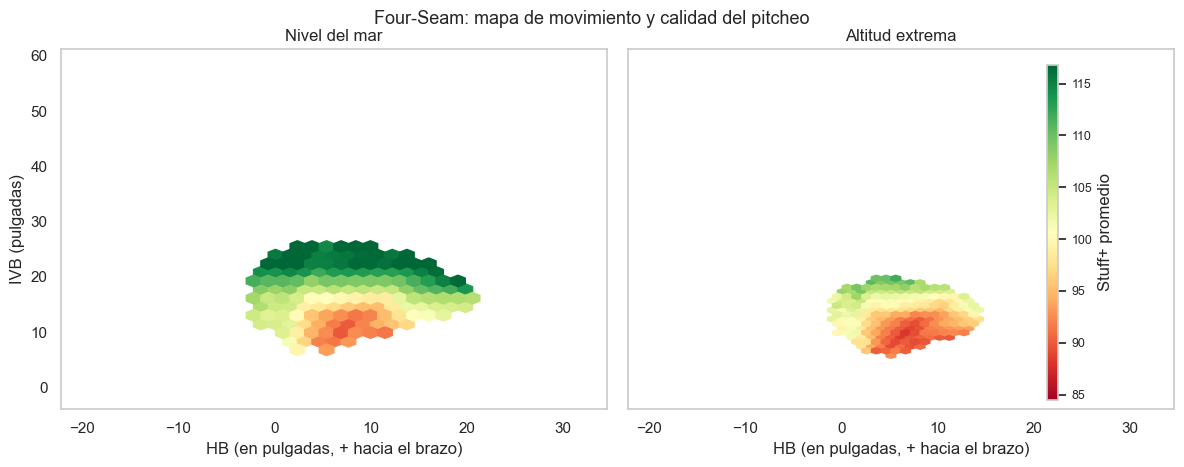

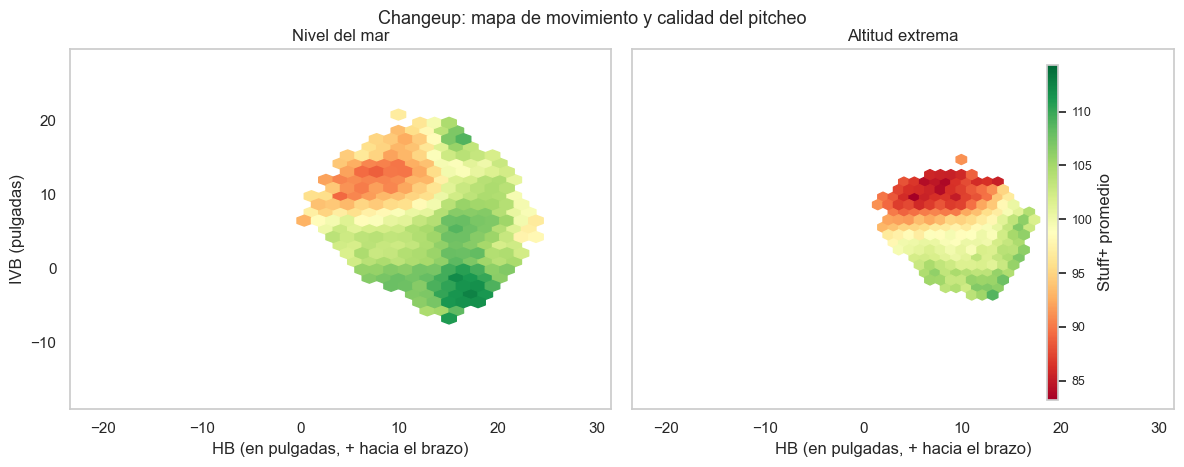

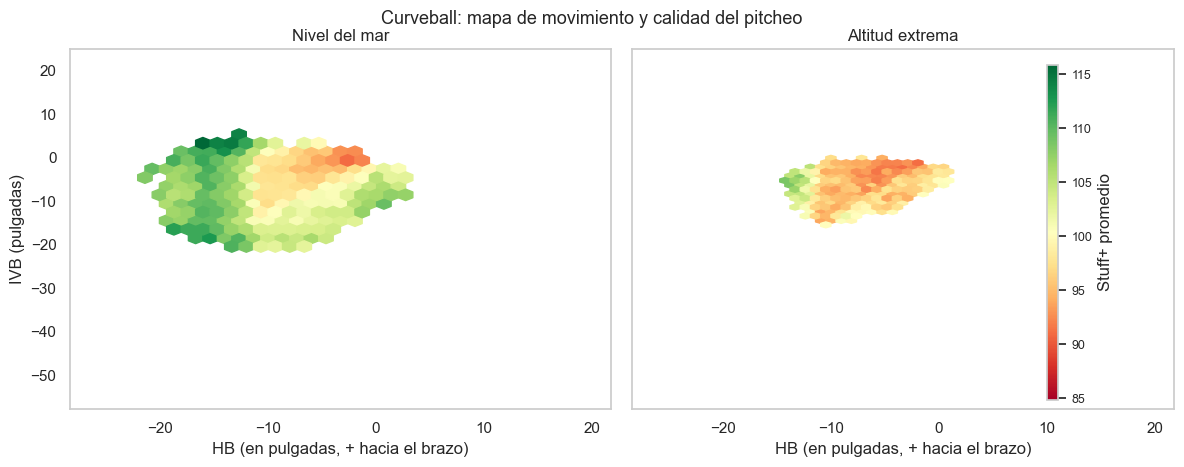

In [81]:
ENV_LABEL = {SEA: "Nivel del mar", EXTREME: "Altitud extrema"}

def fig_mapa_movimiento(df, pt="Four-Seam"):
    d = df[(df[PT] == pt) & df["Stuff_Plus"].notna()]
    
    # Tamaño de figura equilibrado para que los paneles respiren
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    
    vmin, vmax = d["Stuff_Plus"].quantile(.05), d["Stuff_Plus"].quantile(.95)
    hexbin = None
    
    for ax, env in zip(axes, [SEA, EXTREME]):
        s = d[d[ALT] == env]
        hexbin = ax.hexbin(
            s["HorzBreak_m"], s["InducedVertBreak"], 
            C=s["Stuff_Plus"], reduce_C_function=np.mean, gridsize=34,
            mincnt=25, cmap="RdYlGn", vmin=vmin, vmax=vmax
        )
        ax.set(title=ENV_LABEL[env])
        ax.grid(False)
    
    axes[0].set_xlabel("HB (en pulgadas, + hacia el brazo)")
    axes[1].set_xlabel("HB (en pulgadas, + hacia el brazo)")
    axes[0].set_ylabel("IVB (pulgadas)")

    # Margen derecho en 0.90 para dejar espacio perfecto a la barra de color
    fig.subplots_adjust(
        left=0.07, right=0.90, top=0.82, bottom=0.15, wspace=0.12
    )

    if hexbin is not None:
        # Al pasar ax=axes sin 'shrink', la barra abarcará toda la altura de los dos subplots
        colorbar = fig.colorbar(
            hexbin,
            ax=axes,
            orientation="vertical",
            location="right",
            fraction=0.025,  # Controla el grosor de la barra
            pad=0.03,        # Distancia entre los gráficos y la barra
            aspect=30        # Estiliza la proporción de la barra
        )
        colorbar.set_label("Stuff+ promedio")
        colorbar.ax.tick_params(labelsize=9)

    fig.suptitle(
        f"{pt}: mapa de movimiento y calidad del pitcheo",
        y=0.93,
        fontsize=13,
    )

    savefig(f"mapa_movimiento_{pt}")
    plt.show()

# Tus llamadas
fig_mapa_movimiento(df, pt="Slider")
fig_mapa_movimiento(df, pt="Four-Seam")
fig_mapa_movimiento(df, pt="Changeup")
fig_mapa_movimiento(df, pt="Curveball")

## 10. Efecto de la altitud
El mismo brazo, otro aire: se compara a cada lanzador **contra sí mismo** (≥ 50 pitcheos del tipo en ambos entornos).


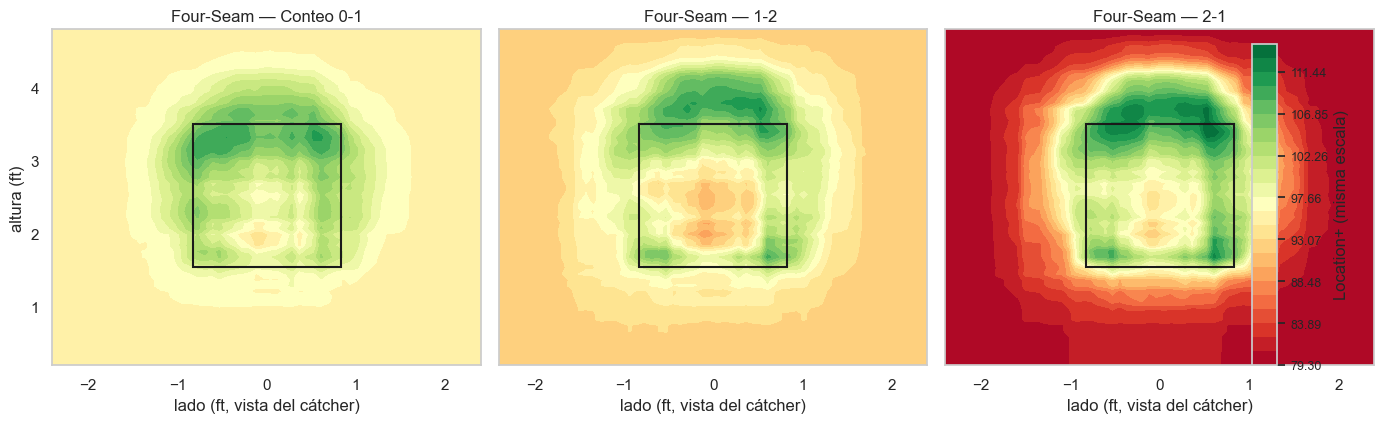

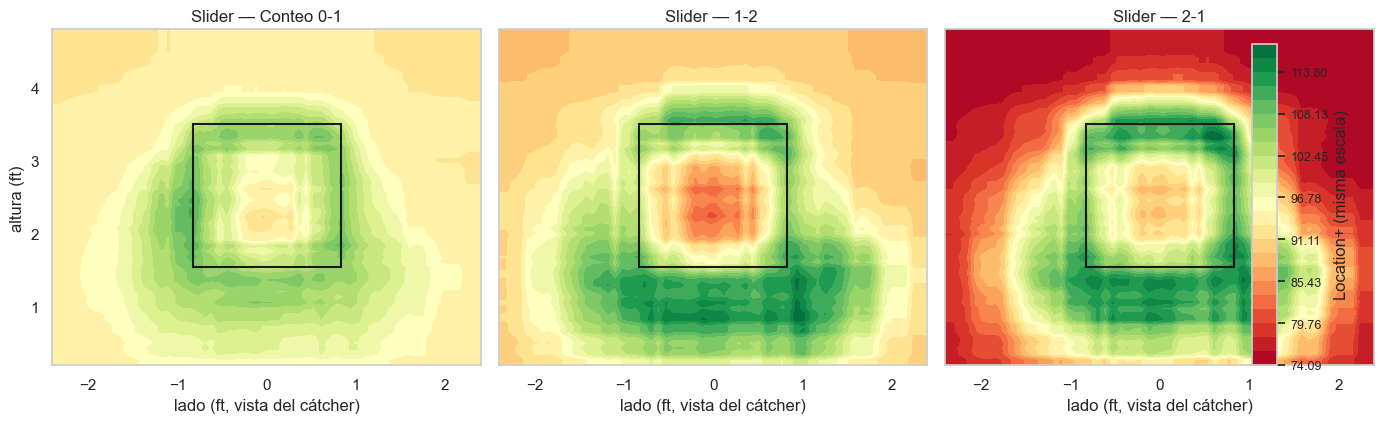

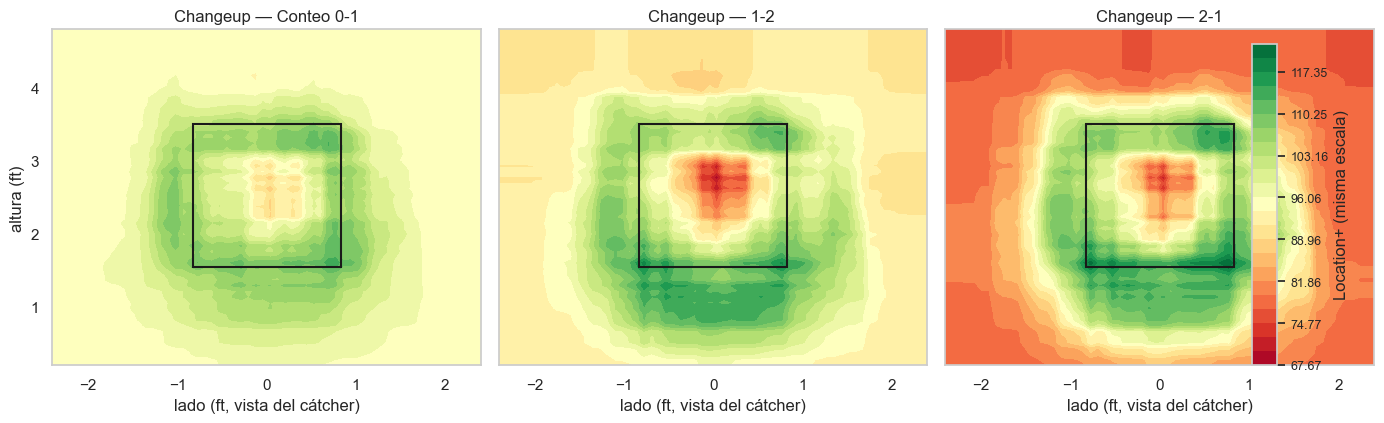

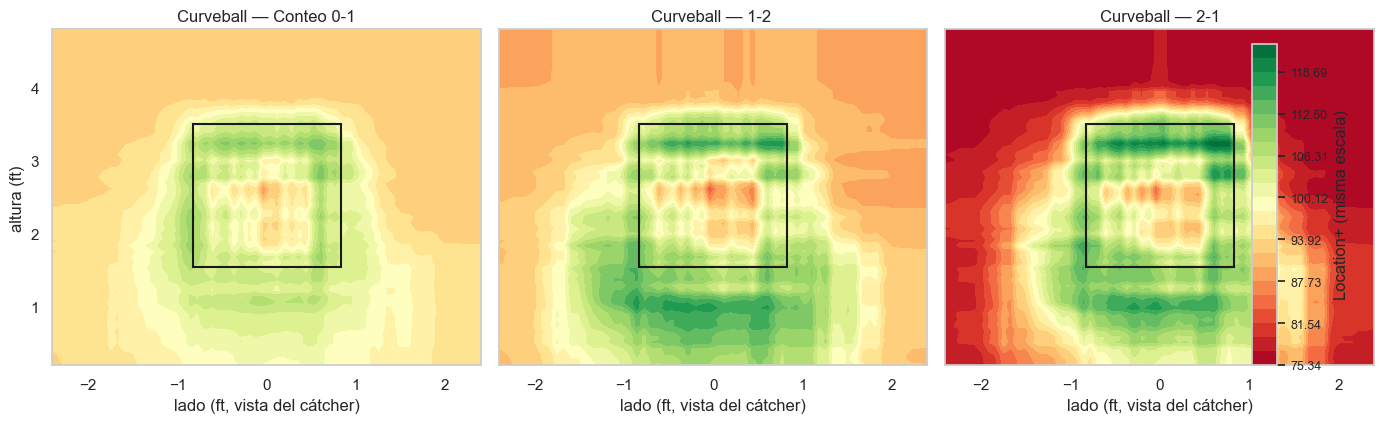

In [82]:
# Mapa de valor de la ubicación (Location+) en el plato, vista del cátcher. Escala de color COMÚN a los tres conteos.
def figure_ZoneLocation(pt_loc=pt_loc):
    side, height = np.meshgrid(np.linspace(-2.4, 2.4, 60), np.linspace(0.2, 4.8, 60))
    COUNTS = [(0, 1, "Conteo 0-1"),(1, 2, "1-2 "), (2, 2, "2-1")]
    bst = LOC_MODELS[pt_loc]
    grids = []

    for b, s_, _ in COUNTS:
        G = pd.DataFrame({
            "PlateLocHeight": height.ravel(),
            "PlateLocSide": side.ravel(),
            "Balls": float(b),
            "Strikes": float(s_),
            "same_hand": 0.0,
        })
        P = _predict(bst, G[feature_list(bst, LOC_FEATURES)].astype("float32"))
        xr = (P * rv_by_count(G["Balls"], G["Strikes"], LOC_RV_ARR, LOC_RV_NEUTRAL)).sum(1)
        grids.append((100 - 10 * (xr - LOC_MU_SD[pt_loc][0]) / LOC_MU_SD[pt_loc][1]).reshape(side.shape))

    levels = np.linspace(min(g.min() for g in grids), max(g.max() for g in grids), 24)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)

    for ax, z, (_, _, ttl) in zip(axes, grids, COUNTS):
        cs = ax.contourf(side, height, z, levels=levels, cmap="RdYlGn")
        ax.add_patch(plt.Rectangle((-0.83, 1.55), 1.66, 1.95, fill=False, ec="k", lw=1.5))
        ax.set(title=f"{pt_loc} — {ttl}", xlabel="lado (ft, vista del cátcher)")

    axes[0].set_ylabel("altura (ft)")

    # Ajustamos los márgenes de la figura para dejar un pasillo libre a la derecha
    fig.subplots_adjust(left=0.07, right=0.88, top=0.88, bottom=0.15, wspace=0.15)

    # Creamos un eje independiente para la barra de color [izquierda, abajo, ancho, alto]
    cbar_ax = fig.add_axes([0.90, 0.15, 0.018, 0.73]) 
    colorbar = fig.colorbar(cs, cax=cbar_ax)
    colorbar.set_label("Location+ (misma escala)")
    colorbar.ax.tick_params(labelsize=9)

    savefig("12_mapa_valor_ubicacion")
    plt.show()

figure_ZoneLocation(pt_loc="Four-Seam")
figure_ZoneLocation(pt_loc="Slider")
figure_ZoneLocation(pt_loc="Changeup")
figure_ZoneLocation(pt_loc="Curveball")

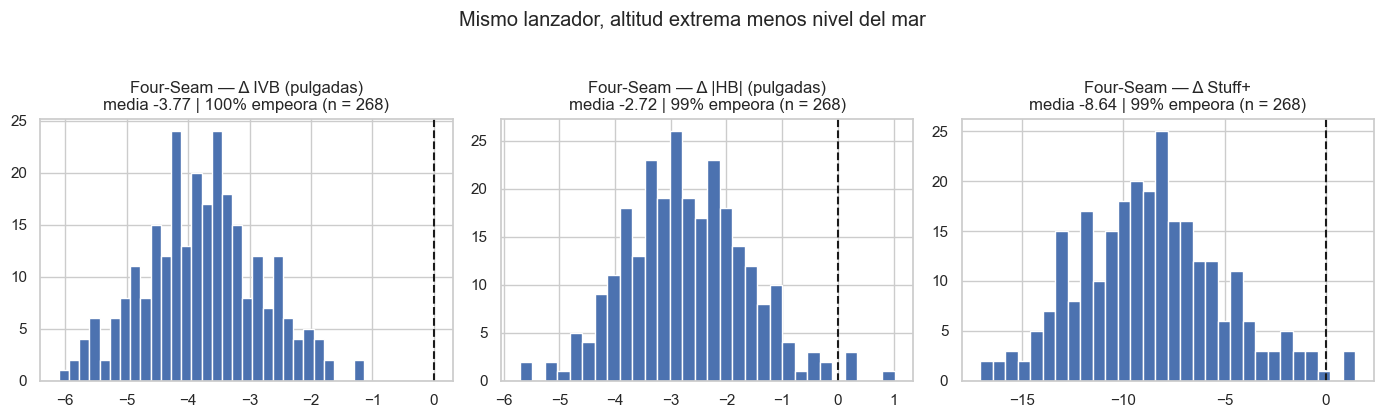

altitude_category,No Altitude,Medium Altitude,Extreme Altitude,Δ (altitud − mar)
AutoPitchType,,,,
Sinker,104.53,96.61,95.05,-9.48
Four-Seam,104.31,97.39,95.80,-8.52
Slider,103.10,98.80,96.72,-6.38
Curveball,103.04,98.24,97.01,-6.03
Changeup,101.84,98.19,96.73,-5.10
Cutter,103.01,100.11,97.96,-5.05


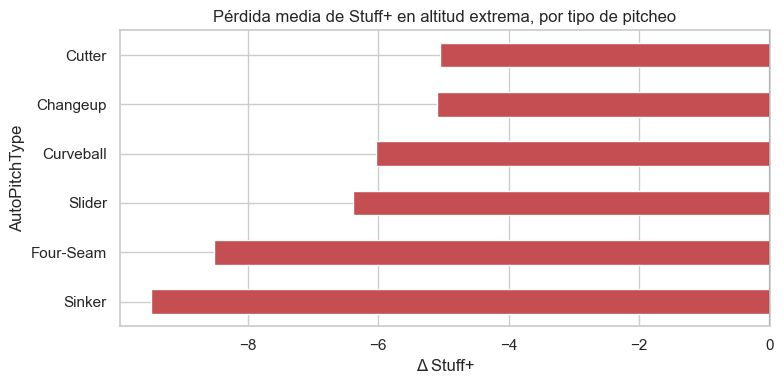

In [83]:
def paired_env(df, pt, col, min_n=50):
    d = df[(df[PT] == pt) & df[ALT].isin([SEA, EXTREME]) & df[col].notna()]
    g = d.groupby([GROUP_COL, ALT])[col].agg(["mean", "size"]).unstack(ALT).dropna()
    g = g[(g[("size", SEA)] >= min_n) & (g[("size", EXTREME)] >= min_n)]
    return g[("mean", EXTREME)] - g[("mean", SEA)]


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
dv = paired_env(df, "Four-Seam", "InducedVertBreak")
dh = paired_env(df.assign(absHB=df["HorzBreak_m"].abs()), "Four-Seam", "absHB")
ds = paired_env(df, "Four-Seam", "Stuff_Plus")
for ax, x, ttl in zip(axes, [dv, dh, ds], ["Δ IVB (pulgadas)", "Δ |HB| (pulgadas)", "Δ Stuff+"]):
    ax.hist(x, bins=30, color="#4C72B0", edgecolor="white")
    ax.axvline(0, color="k", ls="--")
    ax.set(title=f"Four-Seam — {ttl}\nmedia {x.mean():.2f} | {100 * (x < 0).mean():.0f}% empeora (n = {len(x)})")
fig.suptitle("Mismo lanzador, altitud extrema menos nivel del mar", y=1.04)
savefig("13_efecto_altitud_four_seam")

# Stuff+ por tipo y entorno
env_tab = df.groupby([PT, ALT])["Stuff_Plus"].mean().unstack(ALT)[[SEA, "Medium Altitude", EXTREME]].dropna()
env_tab["Δ (altitud − mar)"] = env_tab[EXTREME] - env_tab[SEA]
display(env_tab.sort_values("Δ (altitud − mar)").round(2))
fig, ax = plt.subplots(figsize=(8, 4))
env_tab["Δ (altitud − mar)"].sort_values().plot.barh(ax=ax, color="#C44E52")
ax.axvline(0, color="k")
ax.set(title="Pérdida media de Stuff+ en altitud extrema, por tipo de pitcheo", xlabel="Δ Stuff+")
savefig("14_perdida_por_tipo")


## 10b. ¿Cómo le iría en la altura a quien nunca ha lanzado ahí? (proyección y su prueba)
Es la pregunta central de reclutamiento. Se traslada la **forma** de cada pitcheo al aire de altitud extrema
(IVB y HB escalan con la ley de Magnus, `k = 1.841`, la del Traductor) y se vuelve a puntuar con el mismo modelo.

**No se asume que funcione: se prueba.** Con los lanzadores que tienen muestra en los dos entornos se compara, SIN usar lo
que hicieron en altitud para proyectar:
1. forma: el Stuff+ proyectado desde nivel del mar contra el Stuff+ que de verdad tuvieron en altitud;
2. resultado: ¿la proyección predice su **whiff real en altitud** mejor que el Stuff+ de nivel del mar sin proyectar?
   (si no lo hace, la proyección no agrega nada y el producto no debe venderla).

Límite: este modelo no usa densidad, así que la proyección capta la **pérdida de forma**, no el efecto extra del aire
sobre el contacto (carry de la pelota). Para carreras sigue valiendo el Impuesto de Altitud.


Densidad objetivo (media medida en altitud extrema): 0.854 | k = 1.841


,valor
pares lanzador–tipo con muestra en ambos entornos,707.000
"sesgo SIN proyectar (mar − altitud real), puntos",7.964
"sesgo CON proyección (proyectado − altitud real), puntos",-1.294
"r(Stuff+ mar, Stuff+ altitud real)",0.794
"r(Stuff+ proyectado, Stuff+ altitud real)",0.833
"r(Stuff+ mar, whiff real en altitud)",0.243
"r(Stuff+ proyectado, whiff real en altitud)",0.283
"r(whiff observado en mar, whiff real en altitud) [referencia]",0.415


Ganancia de proyectar (r proyectado − r mar) sobre el whiff real en altitud: +0.040  IC95% [-0.003, +0.083]
-> NO se puede afirmar que la proyección aporte sobre el Stuff+ de nivel del mar con estos datos.


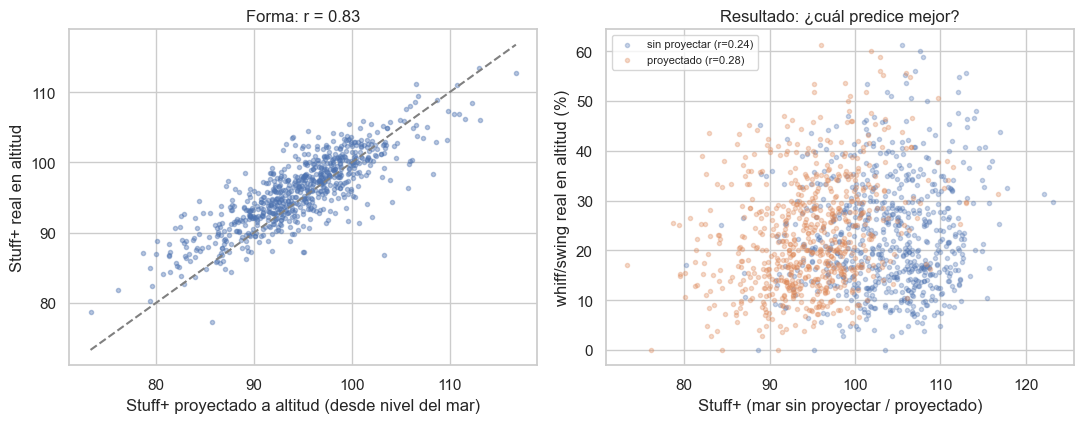

In [84]:
PROJECT_K = 1.841
SHAPE_COLS = ["InducedVertBreak", "HorzBreak_m", "ivb_diff_env", "hb_diff_env"]
TARGET_DENSITY = float(df.loc[df[ALT] == EXTREME, "density_index"].mean())
print(f"Densidad objetivo (media medida en altitud extrema): {TARGET_DENSITY:.3f} | k = {PROJECT_K}")
def stuff_from_X(bst, pt, X, rv_neutral=STUFF_RV_NEUTRAL):
    X = clip_stuff_features(X, pt)
    feats = feature_list(bst, STUFF_FEATURES)

    if "same_hand" in feats:
        p = P_SAME[pt]

        P = (
            (1 - p) * _predict(
                bst,
                X.assign(same_hand=0.0),
            )
            + p * _predict(
                bst,
                X.assign(same_hand=1.0),
            )
        )
    else:
        P = _predict(bst, X)

    mu, sd = STUFF_MU_SD[pt]

    # Stuff+ monotónico: el booster ya predice xRV directamente.
    # Modelos multiclass antiguos: convertir probabilidades a xRV.
    if P.shape[1] == 1:
        xrv = P[:, 0]
    elif P.shape[1] == len(rv_neutral):
        xrv = P @ rv_neutral
    else:
        raise ValueError(
            f"Salida inesperada del booster {pt}: "
            f"{P.shape}; clases esperadas: {len(rv_neutral)}"
        )

    return np.asarray(
        100 - 10 * (xrv - mu) / sd,
        dtype=float,
    ).reshape(-1)

def score_projected(df, target=TARGET_DENSITY):
    """Stuff+ de cada pitcheo como si se hubiera lanzado a la densidad `target` (modelo final, neutral a la mano)."""
    out = pd.Series(np.nan, index=df.index)
    base = (df["valid_hand"] & df[STUFF_CORE].notna().all(axis=1)
            & df[[GROUP_COL, "year", ALT]].notna().all(axis=1)
            & df["density_index"].notna())
    for pt, bst in STUFF_MODELS.items():
        m = base & (df[PT] == pt)
        if not m.any():
            continue
        X = df.loc[m, feature_list(bst, STUFF_FEATURES)].astype("float32")
        X = clip_stuff_features(X, pt)
        fac = ((target / df.loc[m, "density_index"].clip(0.70, 1.05)) ** PROJECT_K).to_numpy()
        for c in SHAPE_COLS:
            if c in X.columns:
                X[c] = X[c] * fac
        out[m] = stuff_from_X(bst, pt, X)
    return out


df["Stuff_proj_alt"] = score_projected(df)

# ---- Prueba con lanzadores medidos en los dos entornos (proyección hecha SOLO con sus pitcheos a nivel del mar)
MIN_N, MIN_SW = 50, 20
sea_d = df[(df[ALT] == SEA) & df["Stuff_proj_alt"].notna() & df["Stuff_Plus_final"].notna()]
alt_d = df[(df[ALT] == EXTREME) & df["Stuff_Plus_final"].notna()]
a = sea_d.groupby([GROUP_COL, PT]).agg(sea=("Stuff_Plus_final", "mean"), proj=("Stuff_proj_alt", "mean"), n_sea=("Stuff_proj_alt", "size"))
b = alt_d.groupby([GROUP_COL, PT]).agg(obs_alt=("Stuff_Plus_final", "mean"), n_alt=("Stuff_Plus_final", "size"))
w_alt = alt_d[alt_d["is_swing"]].groupby([GROUP_COL, PT]).agg(whiff_alt=("is_whiff", "mean"), sw_alt=("is_whiff", "size"))
w_sea = sea_d[sea_d["is_swing"]].groupby([GROUP_COL, PT]).agg(whiff_sea=("is_whiff", "mean"), sw_sea=("is_whiff", "size"))
V = a.join(b, how="inner").join(w_alt, how="left").join(w_sea, how="left").reset_index()
V = V[(V["n_sea"] >= MIN_N) & (V["n_alt"] >= MIN_N)].copy()
for c in ["sea", "proj", "obs_alt", "whiff_alt", "whiff_sea"]:                      # centrar por tipo antes de juntar
    V[c + "_c"] = V[c] - V.groupby(PT)[c].transform("mean")
Vw = V[(V["sw_alt"] >= MIN_SW) & (V["sw_sea"] >= MIN_SW)]
cr = lambda x, y: float(np.corrcoef(x, y)[0, 1]) if len(x) > 10 else np.nan
rows = {
    "pares lanzador–tipo con muestra en ambos entornos": len(V),
    "sesgo SIN proyectar (mar − altitud real), puntos": float((V["sea"] - V["obs_alt"]).mean()),
    "sesgo CON proyección (proyectado − altitud real), puntos": float((V["proj"] - V["obs_alt"]).mean()),
    "r(Stuff+ mar, Stuff+ altitud real)": cr(V["sea_c"], V["obs_alt_c"]),
    "r(Stuff+ proyectado, Stuff+ altitud real)": cr(V["proj_c"], V["obs_alt_c"]),
    "r(Stuff+ mar, whiff real en altitud)": cr(Vw["sea_c"], Vw["whiff_alt_c"]),
    "r(Stuff+ proyectado, whiff real en altitud)": cr(Vw["proj_c"], Vw["whiff_alt_c"]),
    "r(whiff observado en mar, whiff real en altitud)  [referencia]": cr(Vw["whiff_sea_c"], Vw["whiff_alt_c"]),
}
check_proj = pd.Series(rows, name="valor")
display(check_proj.round(3).to_frame())

# ¿La proyección mejora a "no proyectar" para predecir el whiff en altitud? IC por bootstrap de lanzadores
rng_b = np.random.default_rng(0)
pids = Vw[GROUP_COL].unique()
by_p = {p: g for p, g in Vw.groupby(GROUP_COL)}
diffs = []
for _ in range(400):
    smp = pd.concat([by_p[p] for p in rng_b.choice(pids, len(pids))])
    diffs.append(cr(smp["proj_c"], smp["whiff_alt_c"]) - cr(smp["sea_c"], smp["whiff_alt_c"]))
lo, hi = np.nanpercentile(diffs, [2.5, 97.5])
gain = rows["r(Stuff+ proyectado, whiff real en altitud)"] - rows["r(Stuff+ mar, whiff real en altitud)"]
print(f"Ganancia de proyectar (r proyectado − r mar) sobre el whiff real en altitud: {gain:+.3f}  IC95% [{lo:+.3f}, {hi:+.3f}]")
print("-> La proyección aporta" if lo > 0 else "-> NO se puede afirmar que la proyección aporte sobre el Stuff+ de nivel del mar con estos datos.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(V["proj"], V["obs_alt"], s=9, alpha=.4)
lims = [V[["proj", "obs_alt"]].min().min(), V[["proj", "obs_alt"]].max().max()]
axes[0].plot(lims, lims, "--", color="gray")
axes[0].set(xlabel="Stuff+ proyectado a altitud (desde nivel del mar)", ylabel="Stuff+ real en altitud",
            title=f"Forma: r = {rows['r(Stuff+ proyectado, Stuff+ altitud real)']:.2f}")
axes[1].scatter(Vw["sea"], 100 * Vw["whiff_alt"], s=9, alpha=.3, label=f"sin proyectar (r={rows['r(Stuff+ mar, whiff real en altitud)']:.2f})")
axes[1].scatter(Vw["proj"], 100 * Vw["whiff_alt"], s=9, alpha=.3, label=f"proyectado (r={rows['r(Stuff+ proyectado, whiff real en altitud)']:.2f})")
axes[1].set(xlabel="Stuff+ (mar sin proyectar / proyectado)", ylabel="whiff/swing real en altitud (%)", title="Resultado: ¿cuál predice mejor?")
axes[1].legend(fontsize=8)
savefig("13b_prueba_proyeccion")


In [85]:
# Candidatos que NO tienen muestra en altitud: ranking de Stuff+ proyectado, en la escala "100 = promedio de altitud"
mu_alt = alt_d.groupby(PT)["Stuff_Plus_final"].agg(["mean", "std"])
c = df[(df[ALT] != EXTREME) & df["Stuff_proj_alt"].notna()].copy()
c["proj_env"] = 100 + 10 * (c["Stuff_proj_alt"] - c[PT].map(mu_alt["mean"])) / c[PT].map(mu_alt["std"])
cand = c.groupby([GROUP_COL, "year"]).agg(n_pitcheos=("proj_env", "size"), stuff_mar=("Stuff_Plus_final", "mean"),
                                           proyectado_en_altitud=("Stuff_proj_alt", "mean"), proj_env=("proj_env", "mean")).reset_index()
alt_n = alt_d.groupby([GROUP_COL, "year"]).size().rename("n_alt").reset_index()
cand = cand.merge(alt_n, on=[GROUP_COL, "year"], how="left").fillna({"n_alt": 0})
cand = cand[(cand["n_pitcheos"] >= 100) & (cand["n_alt"] < MIN_N)]           # sin muestra real en altitud
cand["cambio_esperado"] = cand["proyectado_en_altitud"] - cand["stuff_mar"]
cand["lanzador"] = cand[GROUP_COL].map(label)
print("Mejores candidatos SIN muestra en altitud, por Stuff+ proyectado (100 = promedio de altitud):")
display(cand.sort_values("proj_env", ascending=False).head(15)[["lanzador", "year", "n_pitcheos", "stuff_mar", "proyectado_en_altitud", "proj_env", "cambio_esperado"]].round(1))
print("Los que MÁS pierden al proyectar (perfil de ride alto: el activo caro que menos aguanta):")
display(cand.sort_values("cambio_esperado").head(8)[["lanzador", "year", "stuff_mar", "proyectado_en_altitud", "cambio_esperado"]].round(1))
cand.to_csv(os.path.join(OUT_DIR, "candidatos_proyectados_a_altitud.csv"), index=False)


Mejores candidatos SIN muestra en altitud, por Stuff+ proyectado (100 = promedio de altitud):


,lanzador,year,n_pitcheos,stuff_mar,proyectado_en_altitud,proj_env,cambio_esperado
1022,pitcher_00768,2025,117,118.7,108.8,115.1,-10.0
133,pitcher_00107,2026,244,113.4,107.0,114.6,-6.3
1442,pitcher_01078,2026,320,113.9,106.4,112.5,-7.5
295,pitcher_00225,2026,191,112.6,107.9,111.9,-4.7
727,pitcher_00548,2025,505,109.0,107.0,111.2,-2.0
625,pitcher_00469,2026,242,115.8,106.2,111.2,-9.6
603,pitcher_00456,2026,186,111.6,105.6,110.9,-6.0
64,pitcher_00054,2024,670,111.4,104.6,110.6,-6.9
556,pitcher_00420,2026,164,108.2,105.5,110.5,-2.8
834,pitcher_00626,2026,330,111.5,105.3,110.4,-6.2


Los que MÁS pierden al proyectar (perfil de ride alto: el activo caro que menos aguanta):


,lanzador,year,stuff_mar,proyectado_en_altitud,cambio_esperado
750,pitcher_00563,2026,100.4,84.3,-16.2
464,pitcher_00345,2024,106.9,91.6,-15.3
576,pitcher_00438,2026,105.2,90.3,-14.9
380,pitcher_00285,2026,107.2,93.7,-13.5
1280,pitcher_00963,2025,103.9,90.6,-13.3
416,pitcher_00311,2025,108.4,95.1,-13.2
197,pitcher_00158,2026,104.3,91.1,-13.2
520,pitcher_00392,2025,102.7,89.5,-13.2


## 11. Tarjeta de lanzador y hallazgos


pitcher_00016 - temporada 2026


n  velo   ivb    hb  stuff    loc  whiff
AutoPitchType altitude_category                                           
Changeup      Extreme Altitude    2  90.2   6.7   7.8  100.6   94.3    0.0
              Medium Altitude     2  89.2   8.4   7.4  103.3   96.3    0.5
Curveball     Extreme Altitude    4  81.3  -6.7  -7.7  100.0   90.9    0.0
              No Altitude         3  78.7  -6.6 -10.8   89.9   94.2    0.0
Cutter        Extreme Altitude    3  89.3   5.0  -4.7  107.1  108.6    0.0
              No Altitude        13  89.1   7.4  -5.5  108.9  100.3    0.1
Four-Seam     Extreme Altitude   51  93.6  16.0   2.8  106.8   99.1    0.1
              Medium Altitude    17  93.3  16.8   2.3  108.1   99.6    0.1
              No Altitude        37  93.8  19.1   3.4  114.3   99.2    0.0
Slider        Extreme Altitude   33  88.3   2.7  -5.7  101.2   96.3    0.2
              Medium Altitude     8  87.1   2.5  -5.3  102.0  104.5    0.1
              No Altitude        23  87.5   4.0  -6.6  105.4  103.6    0.2

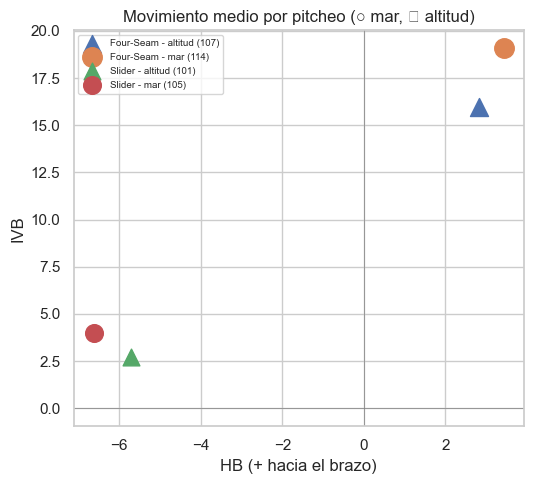

In [86]:
def pitcher_card(pid, year=None):
    year = year or int(df.loc[df[GROUP_COL] == pid, "year"].max())
    d = df[(df[GROUP_COL] == pid) & (df["year"] == year) & df["Stuff_Plus"].notna()]
    if d.empty:
        print("Sin datos:", pid, year); return
    tab = d.groupby([PT, ALT]).agg(n=("Stuff_Plus", "size"), velo=("RelSpeed", "mean"), ivb=("InducedVertBreak", "mean"),
                                   hb=("HorzBreak_m", "mean"), stuff=("Stuff_Plus", "mean"), loc=("Location_Plus", "mean"),
                                   whiff=("is_whiff", "mean")).round(1)
    print(f"{label(pid)} - temporada {year}")
    display(tab)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for (pt, env), g in d.groupby([PT, ALT]):
        if env in (SEA, EXTREME) and len(g) >= 15:
            ax.scatter(g["HorzBreak_m"].mean(), g["InducedVertBreak"].mean(), s=40 + 4 * g["Stuff_Plus"].mean() - 300,
                       marker="o" if env == SEA else "^", label=f"{pt} - {'mar' if env == SEA else 'altitud'} ({g['Stuff_Plus'].mean():.0f})")
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ax.set(xlabel="HB (+ hacia el brazo)", ylabel="IVB", title="Movimiento medio por pitcheo (○ mar, △ altitud)")
    ax.legend(fontsize=7)
    savefig(f"15_tarjeta_{pid}")


if len(top_alt):
    pitcher_card('pitcher_00016', 2026)


In [87]:
# Resumen de hallazgos con las cifras de ESTA corrida
brecha = df.groupby(ALT)["Stuff_Plus"].mean()
print("HALLAZGOS")
print(f"- Stuff+ medio: nivel del mar {brecha.get(SEA, np.nan):.1f} | altitud media {brecha.get('Medium Altitude', np.nan):.1f} | "
      f"altitud extrema {brecha.get(EXTREME, np.nan):.1f}")
print(f"- Cuatro-costuras: {100 * (dv < 0).mean():.0f}% de los lanzadores pierde IVB en altitud (media {dv.mean():.2f} in); "
      f"{100 * (ds < 0).mean():.0f}% pierde Stuff+ (media {ds.mean():.2f}).")
print(f"- Persistencia 2023-2024 {r_2023_2024:.2f} | correlación con whiff {r_whiff:.2f}.")
print(f"- Calibración global: pendiente {slope:.2f} (1.0 = perfecta).")
mx = sens.abs().stack().idxmax()
print(f"- Mayor sensibilidad: {mx[1]} en {mx[0]} ({sens.loc[mx[0], mx[1]]:+.2f} puntos de Stuff+).")
print("- Features más influyentes (SHAP, Four-Seam):", ", ".join(shap_tab.get('Four-Seam', pd.Series(dtype=float)).index[-3:][::-1]))
print(f"- Fuente de los puntajes: Stuff+ {SCORE_SOURCE_S}; Location+ {SCORE_SOURCE_L}.")


HALLAZGOS
- Stuff+ medio: nivel del mar 103.6 | altitud media 97.9 | altitud extrema 96.2
- Cuatro-costuras: 100% de los lanzadores pierde IVB en altitud (media -3.77 in); 99% pierde Stuff+ (media -8.64).
- Persistencia 2023-2024 nan | correlación con whiff 0.43.
- Calibración global: pendiente 1.28 (1.0 = perfecta).
- Mayor sensibilidad: +1 mph de velocidad en Curveball (+2.43 puntos de Stuff+).
- Features más influyentes (SHAP, Four-Seam): InducedVertBreak, RelSpeed, RelHeight
- Fuente de los puntajes: Stuff+ modelo publicado: artifacts/models/stuff_plus_final_v1_monotone; Location+ modelo publicado: artifacts/models/location_plus_l3.


Listo. Resultados en: salidas_finales
